# Cyclone Remal paper figures: editable figure-only notebook

This notebook is **only for the figures used in the manuscript**. It does not recalculate the paper's validation statistics.

The organization follows the paper itself:

- **Section 2.2** → Figure 1
- **Section 3.1** → Figure 2
- **Section 3.2** → Figure 3
- **Section 3.3** → Figure 4
- **Section 3.4** → Figure 5
- **Section 3.5** → Figure 6
- **Section 3.6** → Figure 7
- **Section 3.7** → Figure 8

For clustered figures, each manuscript panel has its own subsection and editable plotting code. A final subsection then assembles the components into the **single paper figure** saved to `paper_figures/`.

The notebook reads the CSV/NetCDF products already created by the analysis notebook (`Remal_Analysis.ipynb`) whenever possible. Figures 5 and 6 also read the original WRF, IMERG and CCMP files, but only to rebuild full-domain display fields; Figure 6 needs this because the analysis did not save its gridded comparison fields to NetCDF.

**Workflow:** edit the global settings cell first (values intended for editing carry a `# <----------------------- change this ...` marker), run the setup cells once, edit any plotting cell you want, then rerun only that figure's final assembly cell.

## 2-D map aesthetic lock
All **map-style 2-D panels** use the layout of `wind_gm.py`, the earlier stand-alone wind-map script: serif text, full d02 min/max extent, coastline 0.8, dotted borders 0.4, DMS grid labels, `wspace=0.15`, bold titles with `pad=12`, and the same horizontal colorbar geometry (`[0.25, 0.15, 0.50, 0.03]`). Wind-vector panels use the same 100×100 interpolation grid and black streamlines (`linewidth=0.8`, `density=1.2`, `arrowsize=1.0`). WRF map fields are not land-masked, except in Figure 6, where land is masked to match the ocean-only CCMP verification. Plot-only interpolation fills holes for display; the validation statistics in the analysis notebook are not recalculated or changed.

## Changes in this version (otherwise the original look)
- **Map fonts (Figures 4–8):** text on the 2-D panels (maps and the Figure 8b sections) is sized for the 15 cm printed width, so it prints at about 7–8 pt instead of about 3 pt. Line plots are unchanged. Because the map labels are larger, each map row's colorbar sits just below the lowest grid labels, and longitude labels are every 6° (8° on five-panel rows and Figure 6b).
- **Figures 1 and 2:** original styling, except slightly larger axis, tick and grid labels (`FIG12_LABEL_SIZE`).
- **Figure 6:** land is masked (left white) in all panels, matching the ocean-only CCMP verification in the analysis notebook.
- **Figures 5, 6, 7a:** dashed outline of the 85.0–93.5°E, 15.5–25.5°N verification region.
- **Round color levels** in Figures 5, 6b, 7a and 8b.
- **Figure 7:** no em dashes in panel titles; the initial-time latent heat flux (zero in WRF output) is not plotted.
- **Notebook previews:** assembled Figures 2, 5, 6 and 7 are previewed at `PREVIEW_WIDTH_PX` (1600 px) wide to keep the notebook small; the PNG/PDF files saved to `paper_figures/` remain full 400 dpi.
- **Figure 8:** fixed vertical-velocity contour levels (solid = ascent, dashed = descent) and "center" spelling.

## Global figure settings: edit these first

In [1]:
# ============================================================
# GLOBAL SETTINGS: MAIN "EDIT ME" CELL
# ============================================================

import os
import glob
import numpy as np
import pandas as pd
import xarray as xr
import h5py

from netCDF4 import Dataset
from scipy.interpolate import RegularGridInterpolator, griddata

import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.image as mpimg
import matplotlib.ticker as mticker
import matplotlib.patheffects as pe
from matplotlib.colors import BoundaryNorm

import cartopy.crs as ccrs
import cartopy.feature as cfeature

from PIL import Image
Image.MAX_IMAGE_PIXELS = None   # 400-dpi composites exceed Pillow's default warning size

# 1. Main folders
BASE_DIR = os.path.expanduser("~/Desktop/remaL_portfolio")   # <----------------------- change this to the folder holding your WRF runs and observation data
ANALYSIS_DIR = os.path.join(BASE_DIR, "analysis_outputs")   # <----------------------- change this to the analysis notebook's OUTPUT_DIR

FNL_DIR = os.path.join(BASE_DIR, "fnl")   # <----------------------- change this to your FNL-forced wrfout folder
GFS_DIR = os.path.join(BASE_DIR, "gfs")   # <----------------------- change this to your GFS-forced wrfout folder
CFSV2_DIR = os.path.join(BASE_DIR, "csfv2")   # <----------------------- change this to your CFSv2-forced wrfout folder
ERA5_DIR = os.path.join(BASE_DIR, "era_5")   # <----------------------- change this to your ERA5-forced wrfout folder

CCMP_DIR = os.path.join(BASE_DIR, "CCMP V3.1")   # <----------------------- change this to your CCMP V3.1 folder
IMERG_DIR = os.path.join(BASE_DIR, "GPM_3IMERGHH_07_Remal")   # <----------------------- change this to your IMERG half-hourly HDF5 folder
IMD_CSV = os.path.join(BASE_DIR, "Remal_IMD_Validation .csv")   # <----------------------- change this to your IMD best-track CSV

MODEL_NAMES = ["FNL", "GFS", "CFSv2", "ERA5"]   # <----------------------- change this to your experiment names (must match the MODEL_DIRS keys)

MODEL_DIRS = {   # <----------------------- change this to map each experiment name to its folder
    "FNL": FNL_DIR,
    "GFS": GFS_DIR,
    "CFSv2": CFSV2_DIR,
    "ERA5": ERA5_DIR,
}

# 2. Output
PAPER_FIGURE_DIR = os.path.join(BASE_DIR, "paper_figures")   # <----------------------- change this to where the final figures are saved
COMPONENT_DIR = os.path.join(PAPER_FIGURE_DIR, "components")
PLOT_CACHE_DIR = os.path.join(PAPER_FIGURE_DIR, "plot_cache")

os.makedirs(PAPER_FIGURE_DIR, exist_ok=True)
os.makedirs(COMPONENT_DIR, exist_ok=True)
os.makedirs(PLOT_CACHE_DIR, exist_ok=True)

# Exact wind_gm.py export resolution.
SAVE_DPI = 400   # <----------------------- change this to set the export resolution
SAVE_PDF = True   # <----------------------- change this to False to skip PDF copies
PREVIEW_WIDTH_PX = 1600   # <----------------------- change this to set the notebook preview width of assembled figures (saved files are unaffected)
SHOW_COMPONENTS = True   # <----------------------- change this to False to hide component figures

# 3. Publication style, copied from wind_gm.py
FONT_FAMILY = "serif"   # <----------------------- change this to use a different font
BASE_FONT_SIZE = 10   # <----------------------- change this to set line-plot text size
TITLE_FONT_SIZE = 10   # <----------------------- change this to set title size
PANEL_LABEL_SIZE = 13   # <----------------------- change this to set (a)/(b) label size
LINE_WIDTH = 1.8   # <----------------------- change this to set model line width
REFERENCE_LINE_WIDTH = 2.2   # <----------------------- change this to set IMD/IMERG line width
MARKER_SIZE = 4   # <----------------------- change this to set marker size
GRID_ALPHA = 0.30   # <----------------------- change this to set grid-line transparency

# wind_gm.py geometry
MAP_HEIGHT_IN = 7.0   # <----------------------- change this to set map-row height (inches)
MAP_WIDTH_PER_PANEL_IN = 5.0          # 4 panels -> 20 inches exactly  <----------------------- change this to set map-panel width (inches)
MAP_LEFT = 0.05
MAP_RIGHT = 0.95
MAP_WSPACE = 0.15
MAP_TITLE_PAD = 12
MAP_COASTLINE_WIDTH = 0.8
MAP_BORDER_WIDTH = 0.4
MAP_COLORBAR_RECT = [0.25, 0.15, 0.50, 0.03]
MAP_COLORBAR_LABEL_SIZE = 12
MAP_COLORBAR_LABEL_PAD = 10
MAP_COLORBAR_TICK_SIZE = 9
MAP_COLORBAR_TICK_PAD = 5
MAP_SUPTITLE_SIZE = 16
MAP_SUPTITLE_Y = 0.92

# Exact wind_gm.py streamline settings.
STREAM_GRID_N = 100
STREAM_LINEWIDTH = 0.8
STREAM_DENSITY = 1.2   # <----------------------- change this to thin or densify streamlines
STREAM_ARROWSIZE = 1.0

COLORS = {   # <----------------------- change these to set each source's line colour
    "IMD": "black",
    "IMERG": "black",
    "CCMP": "black",
    "FNL": "tab:red",
    "GFS": "tab:blue",
    "CFSv2": "tab:green",
    "ERA5": "tab:orange",
}

mpl.rcParams.update({
    "font.size": BASE_FONT_SIZE,
    "font.family": FONT_FAMILY,
})

# 3b. PRINT-SIZE FONTS FOR 2-D (MAP / SECTION) PANELS ONLY
# A full-width figure prints 5.9 in (15 cm) wide. Map rows are drawn 20-25 in
# wide, so their text is scaled up to print at these sizes (points on paper).
PRINT_TEXT_WIDTH_IN = 5.9   # <----------------------- change this to your journal's printed figure width (inches)
MAP_PRINT_PT = {"tick": 7.0, "title": 8.0, "cbar_label": 7.5, "cbar_tick": 7.0,   # <----------------------- change these to set printed map font sizes (pt)
                "panel": 9.0, "legend": 7.0, "label": 7.5}
MAP_GRID_LON_STEP = 6.0          # longitude-label spacing on full-d02 maps  <----------------------- change this to space longitude labels
MAP_GRID_LON_STEP_NARROW = 8.0   # five-panel rows and Figure 6b  <----------------------- change this to space longitude labels
MAP_GRID_LAT_STEP = 5.0   # <----------------------- change this to space latitude labels
FIG12_LABEL_SIZE = 12   # Figures 1-2 only: axis/tick/grid labels (original 10); nothing else changes  <----------------------- change this to resize Figure 1-2 labels
M = {}   # current map font sizes (drawing points); set by set_map_print_width()

# 3c. Verification region used by the analysis notebook for all rainfall,
#     CCMP and latent-heat statistics; outlined on Figures 5, 6 and 7a.
VERIF_BOX = {"lon_min": 85.0, "lon_max": 93.5, "lat_min": 15.5, "lat_max": 25.5}   # <----------------------- keep equal to RAINFALL_REGION/DIAGNOSTIC_REGION in the analysis notebook

# 3d. Fixed colour levels (edit freely)
FIG5_ACCUM_LEVELS = np.arange(0, 801, 50);     FIG5_ACCUM_TICKS = np.arange(0, 801, 100)   # <----------------------- change these to set Figure 5a rainfall levels/ticks (mm)
FIG5_DIFF_LEVELS = np.arange(-400, 401, 50);   FIG5_DIFF_TICKS = np.arange(-400, 401, 100)   # <----------------------- change these to set Figure 5b difference levels/ticks (mm)
FIG6_DIFF_LEVELS = np.arange(-20, 20.1, 2.5);  FIG6_DIFF_TICKS = np.arange(-20, 21, 5)   # <----------------------- change these to set Figure 6b difference levels/ticks (m s-1)
FIG7_PW_LEVELS = np.arange(0, 91, 5);          FIG7_PW_TICKS = np.arange(0, 91, 10)   # <----------------------- change these to set Figure 7 PW levels/ticks (mm)
FIG7_RH_LEVELS = np.arange(0, 101, 5);         FIG7_RH_TICKS = np.arange(0, 101, 10)   # <----------------------- change these to set Figure 7 RH850 levels/ticks (%)
FIG8_WIND_LEVELS = np.arange(0, 50.1, 2.5);    FIG8_WIND_TICKS = np.arange(0, 51, 5)   # <----------------------- change these to set Figure 8b wind levels/ticks (m s-1)
# Vertical-velocity contours (m s-1): negative = descent (dashed), positive = ascent (solid)
FIG8_W_LEVELS = [-1.0, -0.5, 0.5, 1.0, 2.0, 4.0]   # <----------------------- change this to set Figure 8b W contours (m s-1)
LH_DROP_INITIAL_TIME = True   # WRF writes LH = 0 at the initial time  <----------------------- change this to False to plot the initial time
LAND_FACE = None              # Figure 6 land is masked but left white (set e.g. "0.82" for grey)  <----------------------- change this to shade land

# 4. Times used in the manuscript figures
FIG6_TIME = pd.Timestamp("2024-05-26T12:00:00Z")   # <----------------------- change this to map CCMP/WRF at another time
FIG7_TIME_TEXT = "20240526_1200"   # <----------------------- change this to one of the analysis DIAGNOSTIC_TIMES
FIG8_TIME_TEXT = "20240526_1200"   # <----------------------- change this to one of the analysis DIAGNOSTIC_TIMES

RAIN_START = pd.Timestamp("2024-05-24T00:00:00Z")   # <----------------------- keep equal to EXPECTED_START in the analysis notebook
RAIN_END = pd.Timestamp("2024-05-28T06:00:00Z")   # <----------------------- keep equal to EXPECTED_END in the analysis notebook

# Full d02 geometry: EXACTLY the same extent logic as wind_gm.py,
# i.e. [lons.min(), lons.max(), lats.min(), lats.max()].
_domain_candidates = sorted(glob.glob(os.path.join(FNL_DIR, "wrfout_d02_*")))   # <----------------------- change FNL_DIR/d02 to pick another reference grid
if len(_domain_candidates) == 0:
    raise FileNotFoundError("No FNL wrfout_d02 files were found in " + FNL_DIR)

DOMAIN_REFERENCE_FILE = _domain_candidates[0]
_ds0 = Dataset(DOMAIN_REFERENCE_FILE)
D02_LAT = np.asarray(_ds0.variables["XLAT"][0], dtype=float)
D02_LON = np.asarray(_ds0.variables["XLONG"][0], dtype=float)
_ds0.close()

D02_EXTENT = [
    float(D02_LON.min()),
    float(D02_LON.max()),
    float(D02_LAT.min()),
    float(D02_LAT.max()),
]

# Same regular 100×100 visual grid used by wind_gm.py.
VIS_LON = np.linspace(D02_EXTENT[0], D02_EXTENT[1], STREAM_GRID_N)
VIS_LAT = np.linspace(D02_EXTENT[2], D02_EXTENT[3], STREAM_GRID_N)
VIS_X, VIS_Y = np.meshgrid(VIS_LON, VIS_LAT)

print("Paper figure folder:", PAPER_FIGURE_DIR)
print("Locked full-d02 map extent:", D02_EXTENT)


Paper figure folder: /home/ushmo/Desktop/remaL_portfolio/paper_figures
Locked full-d02 map extent: [76.24794006347656, 99.54637145996094, 3.0208663940429688, 25.44097900390625]


## Shared plotting helpers

In [2]:
def require_file(path):
    if not os.path.exists(path):
        raise FileNotFoundError(
            "Required file was not found:\n"
            + path
            + "\nRun the final analysis notebook first or correct BASE_DIR."
        )
    return path


def format_time_axis(ax):
    ax.xaxis.set_major_formatter(
        mdates.DateFormatter("%d %b\n%H:%M")
    )


def set_map_print_width(fig_width_in, print_width_in=PRINT_TEXT_WIDTH_IN):
    """Set map/section text sizes so they print at MAP_PRINT_PT. Call before drawing each 2-D figure."""
    k = float(fig_width_in) / float(print_width_in)
    M.clear()
    M.update({key: val * k for key, val in MAP_PRINT_PT.items()})
    M["k"] = k   # M["fig"] is bound to the next map figure drawn
    return M


def wind_gm_base_map(ax, left_labels=True, lon_step=None, land_face=None, lat_step=None, label_size=None):
    """Map frame copied from wind_gm.py (grid labels sized for print)."""
    ax.set_extent(D02_EXTENT, crs=ccrs.PlateCarree())
    if land_face is not None:
        ax.add_feature(cfeature.LAND, facecolor=land_face, edgecolor="none", zorder=0)
    ax.add_feature(cfeature.COASTLINE, linewidth=MAP_COASTLINE_WIDTH)
    ax.add_feature(
        cfeature.BORDERS,
        linewidth=MAP_BORDER_WIDTH,
        linestyle=":"
    )

    gl = ax.gridlines(
        draw_labels=True,
        dms=True,
        x_inline=False,
        y_inline=False,
        alpha=0.3
    )
    gl.top_labels = False
    gl.right_labels = False
    gl.left_labels = left_labels
    if label_size is not None:
        # Original grid spacing kept; only the label text is enlarged.
        gl.xlabel_style = {"size": label_size}
        gl.ylabel_style = {"size": label_size}
        return gl
    # Print fonts apply only to the figure created right after set_map_print_width();
    # Figures 1 and 2 never call it, so they keep the original look even if rerun later.
    if M and "fig" not in M:
        M["fig"] = ax.figure
    if M and M.get("fig") is ax.figure:
        step = MAP_GRID_LON_STEP if lon_step is None else lon_step
        gl.xlocator = mticker.FixedLocator(np.arange(78.0 - 60 * step, 181, step))
        lstep = MAP_GRID_LAT_STEP if lat_step is None else lat_step
        gl.ylocator = mticker.FixedLocator(np.arange(5.0 - 40 * lstep, 91, lstep))
        gl.xlabel_style = {"size": M["tick"]}
        gl.ylabel_style = {"size": M["tick"]}
    return gl


def draw_verification_box(ax):
    """Dashed outline of the analysis verification region, visible on any colour scale."""
    b = VERIF_BOX
    lw = 0.9 * M.get("k", 1.0)
    ax.plot([b["lon_min"], b["lon_max"], b["lon_max"], b["lon_min"], b["lon_min"]],
            [b["lat_min"], b["lat_min"], b["lat_max"], b["lat_max"], b["lat_min"]],
            transform=ccrs.PlateCarree(), color="black", linewidth=lw, linestyle=(0, (4, 2.5)), zorder=6,
            path_effects=[pe.Stroke(linewidth=lw * 2.6, foreground="white"), pe.Normal()])


def panel_label_above_title(ax, label, x=-0.16, gap_pt=4.0):
    """Original-style (a)/(b): top-left corner, sitting just above the panel titles."""
    fig = ax.figure
    fig.canvas.draw()
    renderer = fig.canvas.get_renderer()
    title_top = ax.title.get_window_extent(renderer).y1
    y = ax.transAxes.inverted().transform((0, title_top + gap_pt * fig.dpi / 72.0))[1]
    ax.text(x, y, label, transform=ax.transAxes, fontsize=M.get("panel", PANEL_LABEL_SIZE),
            fontweight="bold", va="bottom", ha="left")


def map_title(ax, text):
    ax.set_title(text, fontweight="bold", pad=MAP_TITLE_PAD, fontsize=M.get("title", TITLE_FONT_SIZE))


def wind_gm_map_row(n_panels):
    """Create a 1-row map cluster with the same physical panel size as wind_gm.py."""
    fig, axes = plt.subplots(
        1,
        n_panels,
        figsize=(MAP_WIDTH_PER_PANEL_IN * n_panels, MAP_HEIGHT_IN),   # <----------------------- change this to resize the figure (inches)
        subplot_kw={"projection": ccrs.PlateCarree()}
    )
    fig.subplots_adjust(left=MAP_LEFT, right=MAP_RIGHT, wspace=MAP_WSPACE)
    return fig, np.atleast_1d(axes)


def wind_gm_colorbar(fig, mappable, label, extend="max", ticks=None):
    """
    wind_gm.py colourbar geometry (same x, width and height). With print-size
    map fonts the bar is lowered just below the lowest grid labels so they
    do not collide.
    """
    rect = list(MAP_COLORBAR_RECT)
    if M:
        fig.canvas.draw()
        renderer = fig.canvas.get_renderer()
        inv = fig.transFigure.inverted()
        maps = [a for a in fig.axes if hasattr(a, "projection")]
        y_low = min(a.get_tightbbox(renderer).transformed(inv).y0 for a in maps)
        rect[1] = min(rect[1], y_low - 0.02 - rect[3])
    cbar_ax = fig.add_axes(rect)
    cb = fig.colorbar(
        mappable,
        cax=cbar_ax,
        orientation="horizontal",
        extend=extend
    )
    if ticks is not None:
        cb.set_ticks(ticks)
    cb.set_label(
        label,
        fontsize=M.get("cbar_label", MAP_COLORBAR_LABEL_SIZE),
        labelpad=MAP_COLORBAR_LABEL_PAD
    )
    cb.ax.tick_params(
        labelsize=M.get("cbar_tick", MAP_COLORBAR_TICK_SIZE),
        pad=MAP_COLORBAR_TICK_PAD
    )
    return cb


def panel_label(ax, label, x=-0.10, y=1.08, fontsize=None):
    ax.text(
        x, y, label,
        transform=ax.transAxes,
        fontsize=PANEL_LABEL_SIZE if fontsize is None else fontsize,
        fontweight="bold",
        va="top",
        ha="left"
    )


def save_component(fig, stem):
    png = os.path.join(COMPONENT_DIR, stem + ".png")
    fig.savefig(
        png,
        dpi=SAVE_DPI,
        bbox_inches="tight",
        facecolor="white"
    )
    if SAVE_PDF:
        fig.savefig(
            os.path.join(COMPONENT_DIR, stem + ".pdf"),
            bbox_inches="tight",
            facecolor="white"
        )
    if SHOW_COMPONENTS:
        plt.show()
    else:
        plt.close(fig)
    print("Saved component:", png)
    return png


def save_final(fig, stem):
    png = os.path.join(PAPER_FIGURE_DIR, stem + ".png")
    fig.savefig(
        png,
        dpi=SAVE_DPI,
        bbox_inches="tight",
        facecolor="white"
    )
    print("Saved final PNG:", png)

    if SAVE_PDF:
        pdf = os.path.join(PAPER_FIGURE_DIR, stem + ".pdf")
        fig.savefig(pdf, bbox_inches="tight", facecolor="white")
        print("Saved final PDF:", pdf)

    plt.show()
    return png


def compose_pngs_vertical(
    stem,
    paths,
    gap_px=30,   # <----------------------- change this to set the gap between stacked rows (px)
    align="center",
    fit_to_widest=False
):
    """
    Pixel-preserving vertical composition.

    If fit_to_widest=True, every component is uniformly resized to the
    width of the widest component before stacking. Aspect ratio is kept,
    so text, axes, maps, colorbars and line thicknesses are not stretched
    independently. This removes left/right empty space in mixed figures.
    """
    images = [Image.open(require_file(p)).convert("RGB") for p in paths]

    if fit_to_widest:
        target_width = max(im.width for im in images)
        fitted = []

        for im in images:
            if im.width == target_width:
                fitted.append(im)
            else:
                scale = target_width / float(im.width)
                new_height = int(round(im.height * scale))
                fitted.append(
                    im.resize(
                        (target_width, new_height),
                        Image.Resampling.LANCZOS
                    )
                )

        images = fitted

    width = max(im.width for im in images)
    height = sum(im.height for im in images) + gap_px * (len(images) - 1)
    canvas = Image.new("RGB", (width, height), "white")

    y = 0

    for im in images:
        if align == "left":
            x = 0
        else:
            x = (width - im.width) // 2

        canvas.paste(im, (x, y))
        y += im.height + gap_px

    png = os.path.join(PAPER_FIGURE_DIR, stem + ".png")
    canvas.save(png, dpi=(SAVE_DPI, SAVE_DPI))

    if SAVE_PDF:
        pdf = os.path.join(PAPER_FIGURE_DIR, stem + ".pdf")
        canvas.save(pdf, "PDF", resolution=SAVE_DPI)
        print("Saved final PDF:", pdf)

    print("Saved final PNG:", png)
    # Show a smaller preview in the notebook; the saved PNG/PDF above stay full resolution.
    if canvas.width > PREVIEW_WIDTH_PX:
        preview = canvas.resize(
            (PREVIEW_WIDTH_PX, round(canvas.height * PREVIEW_WIDTH_PX / canvas.width)),
            Image.Resampling.LANCZOS
        )
    else:
        preview = canvas
    display(preview)
    return png


def compose_figure2_png(
    stem,
    top_path,
    left_path,
    right_path,
    gap_px=30   # <----------------------- change this to set the gap between stacked rows (px)
):
    """
    Assemble Figure 2 with exact row-width matching.

    The lower two graph panels are joined first, then uniformly resized
    so their combined width is exactly the width of the upper map row.
    No left/right dead space remains, and the two graph panels keep the
    same relative size and aspect ratio.
    """
    top = Image.open(require_file(top_path)).convert("RGB")
    left = Image.open(require_file(left_path)).convert("RGB")
    right = Image.open(require_file(right_path)).convert("RGB")

    bottom_height = max(left.height, right.height)
    bottom_width = left.width + gap_px + right.width

    bottom = Image.new("RGB", (bottom_width, bottom_height), "white")
    bottom.paste(left, (0, (bottom_height - left.height) // 2))
    bottom.paste(
        right,
        (left.width + gap_px, (bottom_height - right.height) // 2)
    )

    # Uniform scale only. No horizontal stretching.
    if bottom.width != top.width:
        scale = top.width / float(bottom.width)
        new_height = int(round(bottom.height * scale))
        bottom = bottom.resize(
            (top.width, new_height),
            Image.Resampling.LANCZOS
        )

    width = top.width
    height = top.height + gap_px + bottom.height

    canvas = Image.new("RGB", (width, height), "white")
    canvas.paste(top, (0, 0))
    canvas.paste(bottom, (0, top.height + gap_px))

    png = os.path.join(PAPER_FIGURE_DIR, stem + ".png")
    canvas.save(png, dpi=(SAVE_DPI, SAVE_DPI))

    if SAVE_PDF:
        pdf = os.path.join(PAPER_FIGURE_DIR, stem + ".pdf")
        canvas.save(pdf, "PDF", resolution=SAVE_DPI)
        print("Saved final PDF:", pdf)

    print("Saved final PNG:", png)
    # Show a smaller preview in the notebook; the saved PNG/PDF above stay full resolution.
    if canvas.width > PREVIEW_WIDTH_PX:
        preview = canvas.resize(
            (PREVIEW_WIDTH_PX, round(canvas.height * PREVIEW_WIDTH_PX / canvas.width)),
            Image.Resampling.LANCZOS
        )
    else:
        preview = canvas
    display(preview)
    return png


def regrid_nearest(src_lon, src_lat, src_field):
    """Nearest-neighbour regrid to the 100x100 display grid (used for the land mask)."""
    pts = np.column_stack([np.ravel(src_lon), np.ravel(src_lat)])
    return griddata(pts, np.ravel(src_field), (VIS_X, VIS_Y), method="nearest")


def wrf_land_mask(path):
    """True over land, from LANDMASK (1 = land) or XLAND (1 = land, 2 = water)."""
    ds = Dataset(path)
    try:
        if "LANDMASK" in ds.variables:
            return np.asarray(ds.variables["LANDMASK"][0], dtype=float) > 0.5
        if "XLAND" in ds.variables:
            return np.asarray(ds.variables["XLAND"][0], dtype=float) < 1.5
        raise KeyError("Neither LANDMASK nor XLAND found in " + path)
    finally:
        ds.close()


def visual_regrid_fill(src_lon, src_lat, src_field, dst_lon=VIS_LON, dst_lat=VIS_LAT):
    """
    Plot-only interpolation onto the full d02 rectangle.
    Linear interpolation is used first; remaining holes are filled by nearest neighbour.
    This is ONLY for map rendering. It does not alter the paper's validation statistics.
    """
    src_lon = np.asarray(src_lon)
    src_lat = np.asarray(src_lat)
    field = np.asarray(src_field, dtype=float)

    if src_lon.ndim == 1 and src_lat.ndim == 1:
        sx, sy = np.meshgrid(src_lon, src_lat)
    elif src_lon.ndim == 2 and src_lat.ndim == 2:
        sx, sy = src_lon, src_lat
    else:
        raise ValueError("lon/lat must both be 1-D or both be 2-D")

    dx, dy = np.meshgrid(dst_lon, dst_lat)
    valid = np.isfinite(sx) & np.isfinite(sy) & np.isfinite(field)

    points = np.column_stack([sx[valid], sy[valid]])
    values = field[valid]

    linear = griddata(points, values, (dx, dy), method="linear")
    nearest = griddata(points, values, (dx, dy), method="nearest")
    return np.where(np.isfinite(linear), linear, nearest)


def wind_gm_streamline_components(src_lon, src_lat, u, v):
    """Exact wind_gm.py style: interpolate vectors to a 100×100 regular grid."""
    lon = np.asarray(src_lon)
    lat = np.asarray(src_lat)
    u = np.asarray(u, dtype=float)
    v = np.asarray(v, dtype=float)

    valid_u = np.isfinite(lon) & np.isfinite(lat) & np.isfinite(u)
    valid_v = np.isfinite(lon) & np.isfinite(lat) & np.isfinite(v)

    u_interp = griddata(
        (lon[valid_u], lat[valid_u]),
        u[valid_u],
        (VIS_X, VIS_Y),
        method="linear"
    )
    v_interp = griddata(
        (lon[valid_v], lat[valid_v]),
        v[valid_v],
        (VIS_X, VIS_Y),
        method="linear"
    )

    # Keep the linear interpolation first, but fill edge holes so the visual
    # field does not disappear over land/near the rectangular map edge.
    if np.isnan(u_interp).any():
        u_near = griddata(
            (lon[valid_u], lat[valid_u]),
            u[valid_u],
            (VIS_X, VIS_Y),
            method="nearest"
        )
        u_interp = np.where(np.isfinite(u_interp), u_interp, u_near)

    if np.isnan(v_interp).any():
        v_near = griddata(
            (lon[valid_v], lat[valid_v]),
            v[valid_v],
            (VIS_X, VIS_Y),
            method="nearest"
        )
        v_interp = np.where(np.isfinite(v_interp), v_interp, v_near)

    return u_interp, v_interp


## Mixed map + graph figure alignment

Figures **2, 5 and 7** are assembled from saved components with a strict shared-width layout:

- every row begins at the same left edge;
- every row ends at the same right edge;
- graph rows are uniformly resized when necessary to match the map-row width;
- aspect ratio is preserved, so graphs are not stretched sideways.

Figure 6 is stacked without rescaling, so row (b) prints narrower than row (a). Figures 3 and 8 are drawn on a single shared Matplotlib canvas and need no assembly step.

This affects only final figure assembly, not the underlying data or statistics.

# Section 2.2 WRF-ARW configuration and experimental design

## Figure 1. Inner WRF analysis domain (d02, 9 km) and the IMD best-track path of Cyclone Remal from the IMD Cyclone Warning Division report (IMD, 2024). The outer 27-km parent domain was part of the nested integration but is not shown in this diagnostic map.

This figure is not clustered, so the section contains one editable plotting block followed by the final save.

### Figure 1: inner d02 domain and IMD track

Saved final PNG: /home/ushmo/Desktop/remaL_portfolio/paper_figures/Figure_1_Domain_and_IMD_Track.png
Saved final PDF: /home/ushmo/Desktop/remaL_portfolio/paper_figures/Figure_1_Domain_and_IMD_Track.pdf


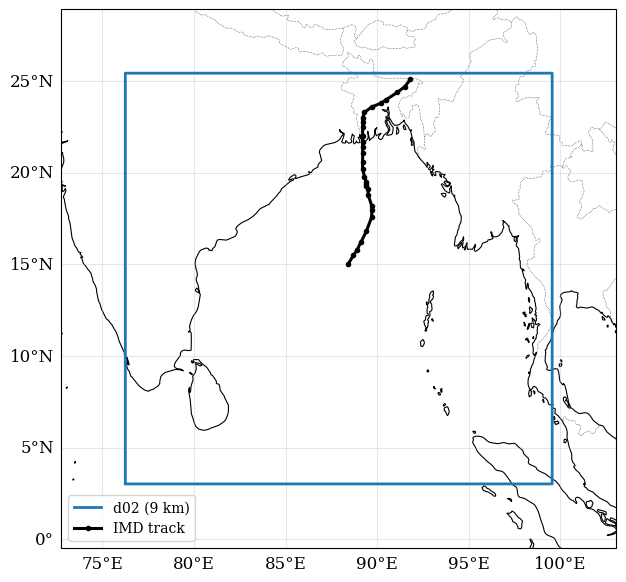

'/home/ushmo/Desktop/remaL_portfolio/paper_figures/Figure_1_Domain_and_IMD_Track.png'

In [3]:
M.clear()   # Figures 1-2 keep the original styling
domain_file = DOMAIN_REFERENCE_FILE
require_file(IMD_CSV)

imd = pd.read_csv(IMD_CSV)
imd["time_utc"] = pd.to_datetime(imd["time_utc"], utc=True)

fig = plt.figure(figsize=(8.2, 7.0))   # <----------------------- change this to resize the figure (inches)
ax = fig.add_subplot(1, 1, 1, projection=ccrs.PlateCarree())
wind_gm_base_map(ax, left_labels=True, label_size=FIG12_LABEL_SIZE)

# Zoom out slightly so the full d02 boundary is visible
ax.set_extent([
    D02_EXTENT[0] - 3.5,   # west  <----------------------- change 3.5 to zoom Figure 1 (degrees)
    D02_EXTENT[1] + 3.5,   # east
    D02_EXTENT[2] - 3.5,   # south
    D02_EXTENT[3] + 3.5    # north
], crs=ccrs.PlateCarree())

edge_lon = np.concatenate([
    D02_LON[0, :],
    D02_LON[1:, -1],
    D02_LON[-1, -2::-1],
    D02_LON[-2:0:-1, 0]
])
edge_lat = np.concatenate([
    D02_LAT[0, :],
    D02_LAT[1:, -1],
    D02_LAT[-1, -2::-1],
    D02_LAT[-2:0:-1, 0]
])

ax.plot(
    edge_lon,
    edge_lat,
    linewidth=2.0,
    label="d02 (9 km)",
    transform=ccrs.PlateCarree()
)
ax.plot(
    imd["longitude"],
    imd["latitude"],
    color=COLORS["IMD"],
    linewidth=REFERENCE_LINE_WIDTH,
    marker="o",
    markersize=3,
    label="IMD track",
    transform=ccrs.PlateCarree()
)
ax.legend(loc="lower left", frameon=True)
# Title left off because the paper caption carries it. Uncomment to add one.
# ax.set_title(
#     "",
#     fontweight="bold",
#     pad=MAP_TITLE_PAD
# )

save_final(fig, "Figure_1_Domain_and_IMD_Track")


# Section 3.1 Cyclone track and translation speed

## Figure 2. Track and motion validation of Cyclone Remal. (a) Simulated cyclone tracks from FNL, GFS, CFSv2, and ERA5 compared with the IMD best track; (b) 6-hourly position error relative to IMD; and (c) cyclone translation speed. Track position statistics use the frozen 6-hourly workflow; the zero translation speeds at the end of the FNL, GFS, and ERA5 series reflect the carried-forward post-landfall positions (Section 4.5).

### (a) Simulated cyclone tracks from FNL, GFS, CFSv2, and ERA5 compared with the IMD best track

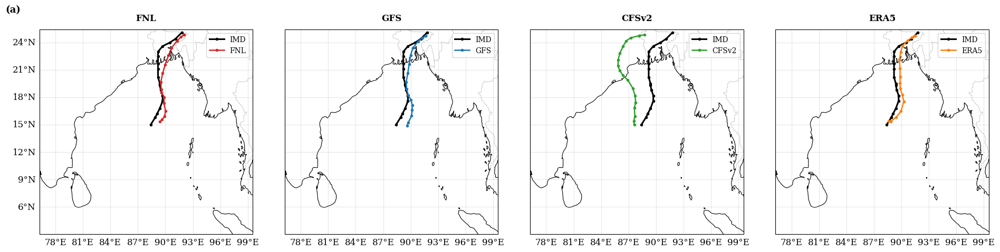

Saved component: /home/ushmo/Desktop/remaL_portfolio/paper_figures/components/Figure_2a_Tracks.png


'/home/ushmo/Desktop/remaL_portfolio/paper_figures/components/Figure_2a_Tracks.png'

In [4]:
track_pairs = {}

for name in MODEL_NAMES:
    path = os.path.join(
        ANALYSIS_DIR,
        "A03_track_validation",
        "Remal_" + name + "_vs_IMD.csv"
    )
    require_file(path)
    table = pd.read_csv(path)
    table["time_utc"] = pd.to_datetime(table["time_utc"], utc=True)
    track_pairs[name] = table


def draw_fig2a_axis(ax, name, left_labels=True):
    p = track_pairs[name]
    wind_gm_base_map(ax, left_labels=left_labels, label_size=FIG12_LABEL_SIZE)

    ax.plot(
        p["lon_imd"], p["lat_imd"],
        color=COLORS["IMD"],
        marker="o",
        markersize=3,
        linewidth=REFERENCE_LINE_WIDTH,
        label="IMD",
        transform=ccrs.PlateCarree()
    )
    ax.plot(
        p["lon_model"], p["lat_model"],
        color=COLORS[name],
        marker="o",
        markersize=3,
        linewidth=LINE_WIDTH,
        label=name,
        transform=ccrs.PlateCarree()
    )
    ax.set_title(name, fontweight="bold", pad=MAP_TITLE_PAD)
    ax.legend(loc="best", frameon=True)


M.clear()   # Figures 1-2 keep the original styling
fig, axes = wind_gm_map_row(4)
for i, name in enumerate(MODEL_NAMES):
    draw_fig2a_axis(axes[i], name, left_labels=(i == 0))

panel_label(axes[0], "(a)", x=-0.16, y=1.12)
save_component(fig, "Figure_2a_Tracks")


### (b) 6-hourly position error relative to IMD

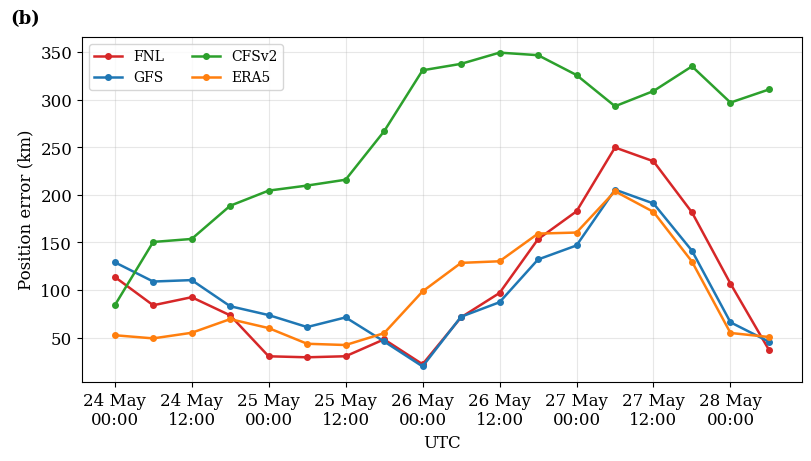

Saved component: /home/ushmo/Desktop/remaL_portfolio/paper_figures/components/Figure_2b_Position_Error.png


'/home/ushmo/Desktop/remaL_portfolio/paper_figures/components/Figure_2b_Position_Error.png'

In [5]:
def draw_fig2b(
    ax
):

    for name in MODEL_NAMES:

        p = track_pairs[name]

        ax.plot(
            p["time_utc"],
            p["track_error_km"],
            color=COLORS[name],
            marker="o",
            markersize=MARKER_SIZE,
            linewidth=LINE_WIDTH,
            label=name
        )

    ax.set_ylabel(
        "Position error (km)"
    )

    ax.set_xlabel(
        "UTC"
    )

    ax.grid(
        alpha=GRID_ALPHA
    )

    ax.legend(
        ncol=2,
        frameon=True
    )

    format_time_axis(
        ax
    )


fig, ax = plt.subplots(
    figsize=(8.0, 4.5),   # <----------------------- change this to resize the figure (inches)
    constrained_layout=True
)

draw_fig2b(
    ax
)

# Slightly larger axis and tick labels only (legend unchanged)
ax.tick_params(labelsize=FIG12_LABEL_SIZE)
ax.xaxis.label.set_size(FIG12_LABEL_SIZE)
ax.yaxis.label.set_size(FIG12_LABEL_SIZE)

panel_label(
    ax,
    "(b)"
)

save_component(
    fig,
    "Figure_2b_Position_Error"
)

### (c) Cyclone translation speed

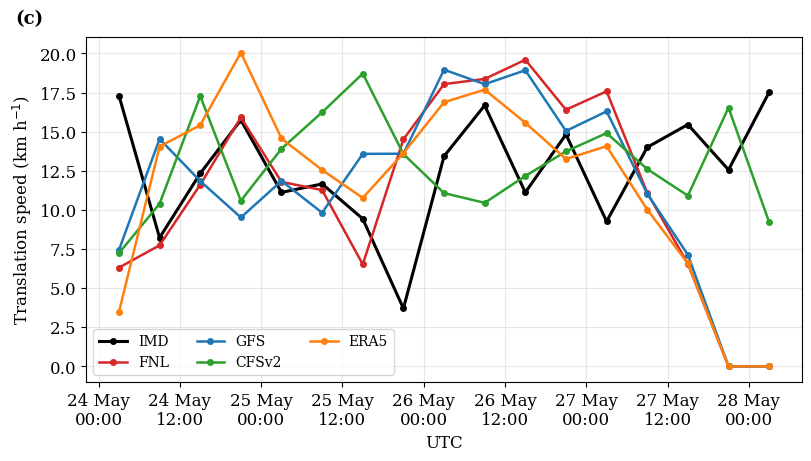

Saved component: /home/ushmo/Desktop/remaL_portfolio/paper_figures/components/Figure_2c_Translation_Speed.png


'/home/ushmo/Desktop/remaL_portfolio/paper_figures/components/Figure_2c_Translation_Speed.png'

In [6]:
translation_path = os.path.join(
    ANALYSIS_DIR,
    "A04_translation_speed",
    "A04_translation_speed_main.csv"
)

require_file(
    translation_path
)

translation = pd.read_csv(
    translation_path
)

for column in [
    "start_time_utc",
    "end_time_utc",
    "mid_time_utc"
]:

    translation[column] = pd.to_datetime(
        translation[column],
        utc=True
    )


def draw_fig2c(
    ax
):

    first = translation[
        translation["model"]
        == MODEL_NAMES[0]
    ]

    ax.plot(
        first["mid_time_utc"],
        first["translation_speed_kmh_imd"],
        color=COLORS["IMD"],
        linewidth=REFERENCE_LINE_WIDTH,
        marker="o",
        markersize=MARKER_SIZE,
        label="IMD"
    )

    for name in MODEL_NAMES:

        s = translation[
            translation["model"]
            == name
        ]

        ax.plot(
            s["mid_time_utc"],
            s["translation_speed_kmh_model"],
            color=COLORS[name],
            linewidth=LINE_WIDTH,
            marker="o",
            markersize=MARKER_SIZE,
            label=name
        )

    ax.set_ylabel(
        "Translation speed (km h$^{-1}$)"
    )

    ax.set_xlabel(
        "UTC"
    )

    ax.grid(
        alpha=GRID_ALPHA
    )

    ax.legend(
        ncol=3,
        frameon=True
    )

    format_time_axis(
        ax
    )


fig, ax = plt.subplots(
    figsize=(8.0, 4.5),   # <----------------------- change this to resize the figure (inches)
    constrained_layout=True
)

draw_fig2c(
    ax
)

# Slightly larger axis and tick labels only (legend unchanged)
ax.tick_params(labelsize=FIG12_LABEL_SIZE)
ax.xaxis.label.set_size(FIG12_LABEL_SIZE)
ax.yaxis.label.set_size(FIG12_LABEL_SIZE)

panel_label(
    ax,
    "(c)"
)

save_component(
    fig,
    "Figure_2c_Translation_Speed"
)

### Final paper Figure 2: assembled (a) + (b) + (c)

Saved final PDF: /home/ushmo/Desktop/remaL_portfolio/paper_figures/Figure_2_Track_and_Motion_Validation.pdf
Saved final PNG: /home/ushmo/Desktop/remaL_portfolio/paper_figures/Figure_2_Track_and_Motion_Validation.png


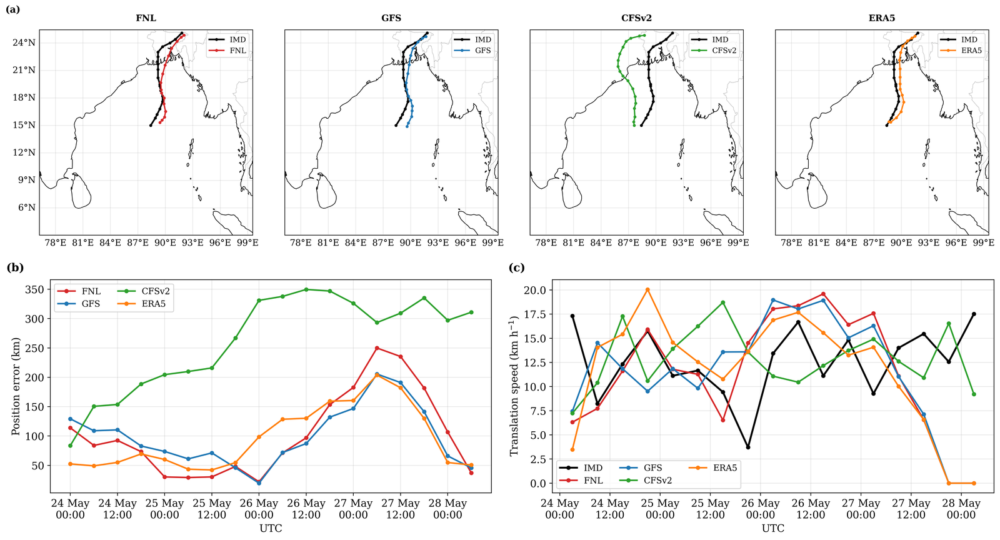

'/home/ushmo/Desktop/remaL_portfolio/paper_figures/Figure_2_Track_and_Motion_Validation.png'

In [7]:
compose_figure2_png(
    "Figure_2_Track_and_Motion_Validation",
    os.path.join(COMPONENT_DIR, "Figure_2a_Tracks.png"),
    os.path.join(COMPONENT_DIR, "Figure_2b_Position_Error.png"),
    os.path.join(COMPONENT_DIR, "Figure_2c_Translation_Speed.png"),
    gap_px=30   # <----------------------- change this to set the gap between stacked rows (px)
)


# Section 3.2 Intensity evolution and peak timing

## Figure 3. Intensity validation against IMD over the 30 exact common timestamps. (a) Maximum 10-m wind within 150 km of the diagnosed center and model-minus-IMD wind bias; (b) simulated central pressure and model-minus-IMD pressure bias.

### (a) Maximum 10-m wind within 150 km of the diagnosed center and model-minus-IMD wind bias

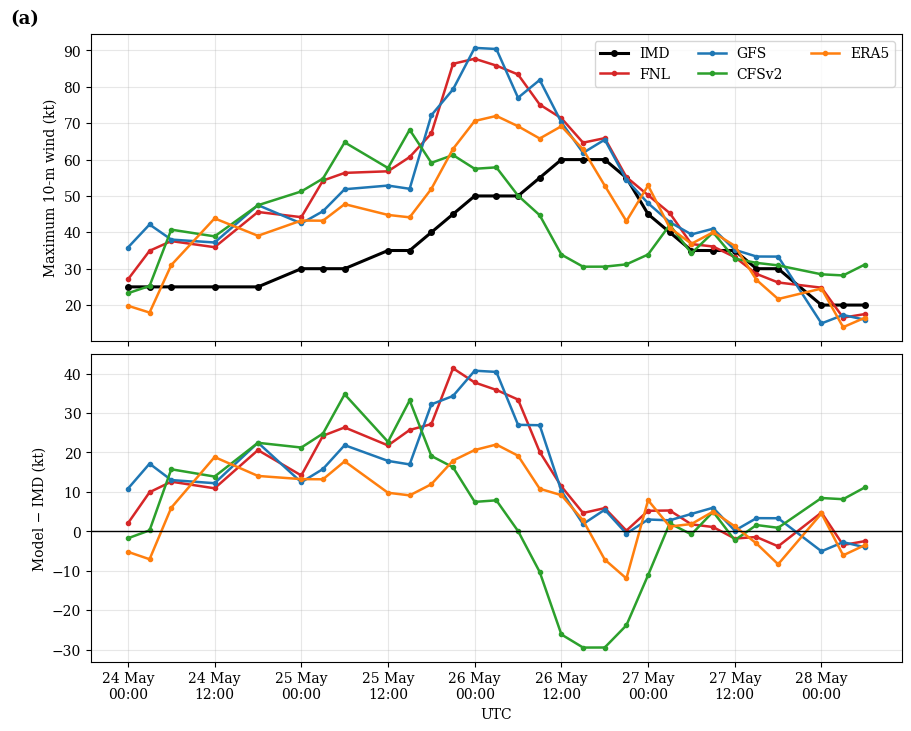

Saved component: /home/ushmo/Desktop/remaL_portfolio/paper_figures/components/Figure_3a_Wind_and_Bias.png


'/home/ushmo/Desktop/remaL_portfolio/paper_figures/components/Figure_3a_Wind_and_Bias.png'

In [8]:
intensity_pairs = {}

for name in MODEL_NAMES:

    path = os.path.join(
        ANALYSIS_DIR,
        "A07_intensity_change",
        "Remal_"
        + name
        + "_All_IMD_Intensity_Matches.csv"
    )

    require_file(
        path
    )

    p = pd.read_csv(
        path
    )

    p["time_utc"] = pd.to_datetime(
        p["time_utc"],
        utc=True
    )

    intensity_pairs[name] = p


def draw_wind_series(
    ax
):

    ref = intensity_pairs[
        MODEL_NAMES[0]
    ]

    ax.plot(
        ref["time_utc"],
        ref["wind_imd"],
        color=COLORS["IMD"],
        linewidth=REFERENCE_LINE_WIDTH,
        marker="o",
        markersize=MARKER_SIZE,
        label="IMD"
    )

    for name in MODEL_NAMES:

        p = intensity_pairs[name]

        ax.plot(
            p["time_utc"],
            p["wind_model"],
            color=COLORS[name],
            linewidth=LINE_WIDTH,
            marker="o",
            markersize=3,
            label=name
        )

    ax.set_ylabel(
        "Maximum 10-m wind (kt)"
    )

    ax.grid(
        alpha=GRID_ALPHA
    )

    ax.legend(
        ncol=3,
        frameon=True
    )


def draw_wind_bias(
    ax
):

    for name in MODEL_NAMES:

        p = intensity_pairs[name]

        ax.plot(
            p["time_utc"],
            p["wind_bias_kt"],
            color=COLORS[name],
            linewidth=LINE_WIDTH,
            marker="o",
            markersize=3,
            label=name
        )

    ax.axhline(
        0,
        color="black",
        linewidth=1
    )

    ax.set_ylabel(
        "Model − IMD (kt)"
    )

    ax.set_xlabel(
        "UTC"
    )

    ax.grid(
        alpha=GRID_ALPHA
    )

    format_time_axis(
        ax
    )


fig, axes = plt.subplots(
    2,
    1,
    figsize=(9.0, 7.2),   # <----------------------- change this to resize the figure (inches)
    sharex=True,
    constrained_layout=True
)

draw_wind_series(
    axes[0]
)

draw_wind_bias(
    axes[1]
)

panel_label(
    axes[0],
    "(a)"
)

save_component(
    fig,
    "Figure_3a_Wind_and_Bias"
)

### (b) Simulated central pressure and model-minus-IMD pressure bias

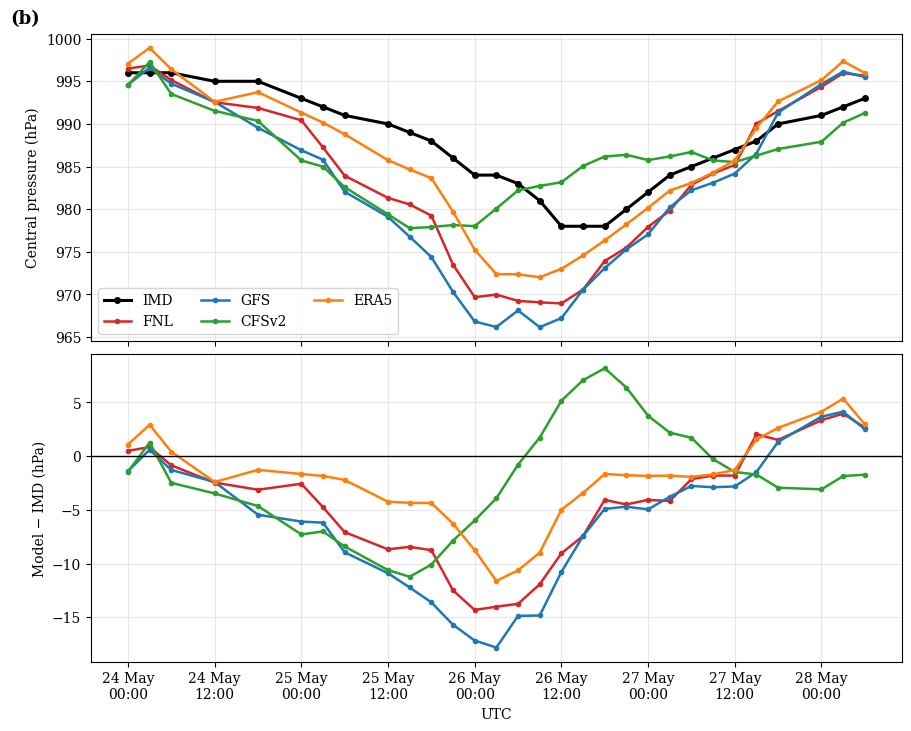

Saved component: /home/ushmo/Desktop/remaL_portfolio/paper_figures/components/Figure_3b_Pressure_and_Bias.png


'/home/ushmo/Desktop/remaL_portfolio/paper_figures/components/Figure_3b_Pressure_and_Bias.png'

In [9]:
def draw_pressure_series(
    ax
):

    ref = intensity_pairs[
        MODEL_NAMES[0]
    ]

    ax.plot(
        ref["time_utc"],
        ref["pres_imd"],
        color=COLORS["IMD"],
        linewidth=REFERENCE_LINE_WIDTH,
        marker="o",
        markersize=MARKER_SIZE,
        label="IMD"
    )

    for name in MODEL_NAMES:

        p = intensity_pairs[name]

        ax.plot(
            p["time_utc"],
            p["pres_model"],
            color=COLORS[name],
            linewidth=LINE_WIDTH,
            marker="o",
            markersize=3,
            label=name
        )

    ax.set_ylabel(
        "Central pressure (hPa)"
    )

    ax.grid(
        alpha=GRID_ALPHA
    )

    ax.legend(
        ncol=3,
        frameon=True
    )


def draw_pressure_bias(
    ax
):

    for name in MODEL_NAMES:

        p = intensity_pairs[name]

        ax.plot(
            p["time_utc"],
            p["pres_bias_hpa"],
            color=COLORS[name],
            linewidth=LINE_WIDTH,
            marker="o",
            markersize=3,
            label=name
        )

    ax.axhline(
        0,
        color="black",
        linewidth=1
    )

    ax.set_ylabel(
        "Model − IMD (hPa)"
    )

    ax.set_xlabel(
        "UTC"
    )

    ax.grid(
        alpha=GRID_ALPHA
    )

    format_time_axis(
        ax
    )


fig, axes = plt.subplots(
    2,
    1,
    figsize=(9.0, 7.2),   # <----------------------- change this to resize the figure (inches)
    sharex=True,
    constrained_layout=True
)

draw_pressure_series(
    axes[0]
)

draw_pressure_bias(
    axes[1]
)

panel_label(
    axes[0],
    "(b)"
)

save_component(
    fig,
    "Figure_3b_Pressure_and_Bias"
)

### Final paper Figure 3: assembled (a) + (b)

Saved final PNG: /home/ushmo/Desktop/remaL_portfolio/paper_figures/Figure_3_Intensity_Validation.png
Saved final PDF: /home/ushmo/Desktop/remaL_portfolio/paper_figures/Figure_3_Intensity_Validation.pdf


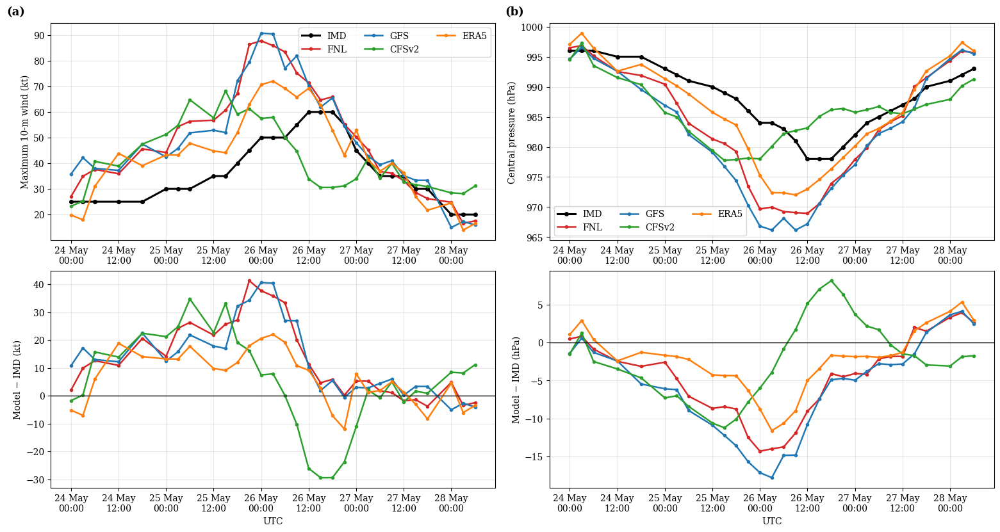

'/home/ushmo/Desktop/remaL_portfolio/paper_figures/Figure_3_Intensity_Validation.png'

In [10]:
fig = plt.figure(
    figsize=(15.5, 8.2),   # <----------------------- change this to resize the figure (inches)
    constrained_layout=True
)

gs = fig.add_gridspec(
    2,
    2
)

ax_wind = fig.add_subplot(
    gs[0, 0]
)

ax_wind_bias = fig.add_subplot(
    gs[1, 0],
    sharex=ax_wind
)

ax_pressure = fig.add_subplot(
    gs[0, 1]
)

ax_pressure_bias = fig.add_subplot(
    gs[1, 1],
    sharex=ax_pressure
)

draw_wind_series(
    ax_wind
)

draw_wind_bias(
    ax_wind_bias
)

draw_pressure_series(
    ax_pressure
)

draw_pressure_bias(
    ax_pressure_bias
)

panel_label(
    ax_wind,
    "(a)"
)

panel_label(
    ax_pressure,
    "(b)"
)

save_final(
    fig,
    "Figure_3_Intensity_Validation"
)

# Section 3.3 Landfall representation and power dissipation

## Figure 4. Observed and simulated coastal crossings. Stars mark the IMD-derived and model-derived landfall points obtained from the respective tracks and the common WRF land mask.

### Figure 4: observed and simulated coastal crossings

Saved final PNG: /home/ushmo/Desktop/remaL_portfolio/paper_figures/Figure_4_Landfall_Crossings.png
Saved final PDF: /home/ushmo/Desktop/remaL_portfolio/paper_figures/Figure_4_Landfall_Crossings.pdf


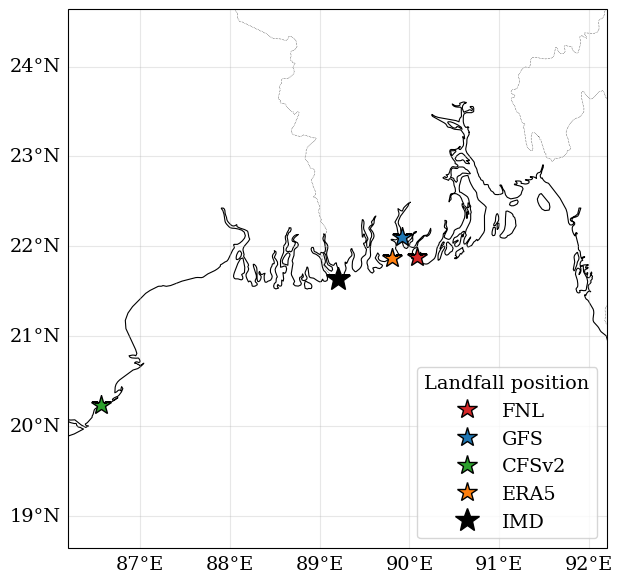

'/home/ushmo/Desktop/remaL_portfolio/paper_figures/Figure_4_Landfall_Crossings.png'

In [11]:
landfall_path = os.path.join(
    ANALYSIS_DIR,
    "A08_landfall",
    "Remal_A6_Landfall_Crossings.csv"
)
require_file(landfall_path)

landfall = pd.read_csv(landfall_path)
landfall["landfall_time_utc"] = pd.to_datetime(
    landfall["landfall_time_utc"],
    utc=True
)

imd_row = landfall[landfall["source"] == "IMD"].iloc[0]

set_map_print_width(8.2, 0.70 * PRINT_TEXT_WIDTH_IN)
fig = plt.figure(figsize=(8.2, 7.0))   # <----------------------- change this to resize the figure (inches)
ax = fig.add_subplot(1, 1, 1, projection=ccrs.PlateCarree())
wind_gm_base_map(ax, left_labels=True, lon_step=1, lat_step=1)

# Zoom in around the landfall region
ax.set_extent([
    float(imd_row["longitude"]) - 3.0,   # west  <----------------------- change 3.0 to zoom Figure 4 (degrees)
    float(imd_row["longitude"]) + 3.0,   # east
    float(imd_row["latitude"]) - 3.0,    # south
    float(imd_row["latitude"]) + 3.0     # north
], crs=ccrs.PlateCarree())

# Plot model landfall stars only
for name in MODEL_NAMES:
    row = landfall[landfall["source"] == name]
    if len(row) == 1:
        row = row.iloc[0]
        ax.plot(
            float(row["longitude"]),
            float(row["latitude"]),
            marker="*",
            markersize=15,
            color=COLORS[name],
            markeredgecolor="black",
            linestyle="none",
            label=name,
            transform=ccrs.PlateCarree()
        )

# Plot IMD landfall star only
ax.plot(
    float(imd_row["longitude"]),
    float(imd_row["latitude"]),
    marker="*",
    markersize=18,
    color="black",
    markeredgecolor="black",
    linestyle="none",
    label="IMD",
    transform=ccrs.PlateCarree()
)

ax.legend(
    loc="lower right",
    fontsize=M["legend"],
    frameon=True,
    title="Landfall position",
    title_fontsize=M["legend"]
)
# Title left off because the paper caption carries it. Uncomment to add one.
# ax.set_title(
#     "Observed and simulated coastal crossings",
#     fontweight="bold",
#     pad=MAP_TITLE_PAD
# )

save_final(fig, "Figure_4_Landfall_Crossings")

# Section 3.4 Rainfall distribution and temporal evolution

## Figure 5. Rainfall validation against IMERG V07B. (a) Common-period accumulated rainfall from IMERG and the four WRF experiments; (b) WRF-minus-IMERG accumulated-rainfall differences; and (c) regional mean rainfall-rate evolution on the common 6-hourly support. The maps show the full d02 domain; the dashed box marks the 85.0–93.5°E, 15.5–25.5°N verification region in which the rainfall statistics (Table 5) and the rain rates in (c) are computed.

**Display-only change in this figure notebook:** the rainfall maps below are regenerated across the full d02 plotting extent so their framing matches `wind_gm.py`. This does not replace or recalculate the manuscript's IMERG statistics, which remain based on the common verification region outlined by the dashed box.

### (a) Common-period accumulated rainfall from IMERG and the four WRF experiments

Loaded cached full-d02 Figure 5 display fields.


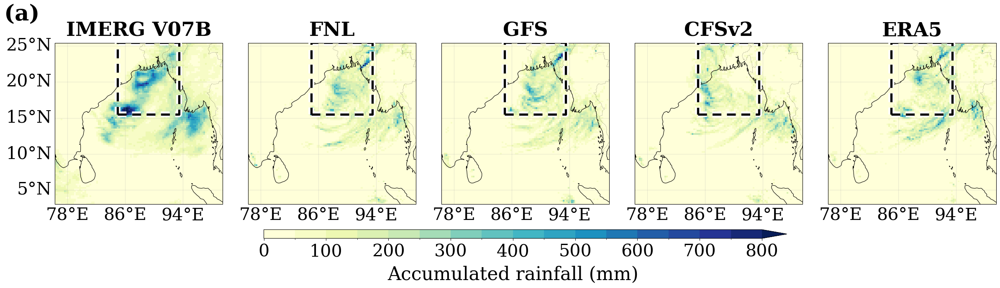

Saved component: /home/ushmo/Desktop/remaL_portfolio/paper_figures/components/Figure_5a_Rainfall_Accumulation.png


'/home/ushmo/Desktop/remaL_portfolio/paper_figures/components/Figure_5a_Rainfall_Accumulation.png'

In [12]:
# ============================================================
# FIGURE 5 PLOT-ONLY FULL-DOMAIN PREPARATION
# The paper statistics remain those produced by the final analysis notebook.
# ============================================================

RAIN_CACHE = os.path.join(PLOT_CACHE_DIR, "Figure5_full_d02_plot_fields.nc")


def _read_imerg_file_for_plot(path):
    with h5py.File(path, "r") as f:
        precip_ds = f["Grid/precipitation"]
        lat = np.asarray(f["Grid/lat"][:], dtype=float)
        lon = np.asarray(f["Grid/lon"][:], dtype=float)
        precip = precip_ds[:]
        fill_value = precip_ds.attrs.get("_FillValue", -9999.9)

        if precip.ndim != 3:
            raise ValueError("Unexpected IMERG precipitation shape: " + str(precip.shape))

        if precip.shape[1] == len(lon) and precip.shape[2] == len(lat):
            field = precip[0].T
        elif precip.shape[1] == len(lat) and precip.shape[2] == len(lon):
            field = precip[0]
        else:
            raise ValueError("Could not resolve IMERG dimension order")

        field = np.asarray(field, dtype=float)
        field[np.isclose(field, fill_value)] = np.nan

        # Get the actual half-hour interval from time_bnds when available.
        if "Grid/time_bnds" in f:
            b = np.ravel(f["Grid/time_bnds"][:])
            units = f["Grid/time"].attrs.get("units", b"")
            if isinstance(units, bytes):
                units = units.decode()
            try:
                epoch = pd.to_datetime(units.split("since")[1].strip(), utc=True)
            except Exception:
                epoch = pd.Timestamp("1980-01-06T00:00:00Z")
            start = epoch + pd.to_timedelta(float(b[0]), unit="s")
            end = epoch + pd.to_timedelta(float(b[1]), unit="s")
        else:
            parts = os.path.basename(path).split(".")
            d = parts[4].split("-")
            ymd = d[0]
            start = pd.to_datetime(ymd + d[1].lstrip("S"), format="%Y%m%d%H%M%S", utc=True)
            end = pd.to_datetime(ymd + d[2].lstrip("E"), format="%Y%m%d%H%M%S", utc=True)

        hours = (end - start) / pd.Timedelta(hours=1)
        return lat, lon, field, start, end, float(hours)


def _full_d02_imerg_accumulation():
    files = sorted(glob.glob(os.path.join(IMERG_DIR, "*.HDF5")))
    if len(files) == 0:
        raise FileNotFoundError("No IMERG .HDF5 files found in " + IMERG_DIR)

    total = None
    lat_out = None
    lon_out = None

    for path in files:
        lat, lon, rate, start, end, hours = _read_imerg_file_for_plot(path)
        if start < RAIN_START or end > RAIN_END:
            continue

        lat_mask = (lat >= D02_EXTENT[2]) & (lat <= D02_EXTENT[3])
        lon_mask = (lon >= D02_EXTENT[0]) & (lon <= D02_EXTENT[1])
        sub = rate[np.ix_(lat_mask, lon_mask)] * hours

        if total is None:
            total = np.zeros_like(sub, dtype=float)
            lat_out = lat[lat_mask]
            lon_out = lon[lon_mask]

        valid = np.isfinite(sub)
        total = np.where(valid, np.nan_to_num(total) + np.where(valid, sub, 0.0), total)

    return lat_out, lon_out, total


def _wrf_total_rain(path):
    ds = Dataset(path)
    total = np.asarray(ds.variables["RAINC"][0], dtype=float) + np.asarray(ds.variables["RAINNC"][0], dtype=float)
    if "I_RAINC" in ds.variables and "I_RAINNC" in ds.variables:
        total = total + (
            np.asarray(ds.variables["I_RAINC"][0], dtype=float)
            + np.asarray(ds.variables["I_RAINNC"][0], dtype=float)
        ) * 100.0
    lat = np.asarray(ds.variables["XLAT"][0], dtype=float)
    lon = np.asarray(ds.variables["XLONG"][0], dtype=float)
    ds.close()
    return total, lat, lon


def _wrf_full_accumulation(model_name):
    start_path = os.path.join(
        MODEL_DIRS[model_name],
        "wrfout_d02_" + RAIN_START.strftime("%Y-%m-%d_%H_%M_%S")
    )
    end_path = os.path.join(
        MODEL_DIRS[model_name],
        "wrfout_d02_" + RAIN_END.strftime("%Y-%m-%d_%H_%M_%S")
    )
    require_file(start_path)
    require_file(end_path)
    a, lat, lon = _wrf_total_rain(start_path)
    b, _, _ = _wrf_total_rain(end_path)
    return lat, lon, b - a


if os.path.exists(RAIN_CACHE):
    _rain = xr.open_dataset(RAIN_CACHE)
    rain_plot_lon = np.asarray(_rain["longitude"].values, dtype=float)
    rain_plot_lat = np.asarray(_rain["latitude"].values, dtype=float)
    imerg_accum = np.asarray(_rain["IMERG_accumulation_mm"].values, dtype=float)
    wrf_accum = {name: np.asarray(_rain[name + "_accumulation_mm"].values, dtype=float) for name in MODEL_NAMES}
    wrf_diff = {name: np.asarray(_rain[name + "_minus_IMERG_mm"].values, dtype=float) for name in MODEL_NAMES}
    _rain.close()
    print("Loaded cached full-d02 Figure 5 display fields.")
else:
    imerg_lat_native, imerg_lon_native, imerg_native = _full_d02_imerg_accumulation()
    imerg_accum = visual_regrid_fill(imerg_lon_native, imerg_lat_native, imerg_native)

    wrf_accum = {}
    wrf_diff = {}
    for name in MODEL_NAMES:
        lat, lon, field = _wrf_full_accumulation(name)
        wrf_accum[name] = visual_regrid_fill(lon, lat, field)
        wrf_diff[name] = wrf_accum[name] - imerg_accum

    rain_plot_lon = VIS_LON.copy()
    rain_plot_lat = VIS_LAT.copy()

    _out = xr.Dataset(coords={"latitude": rain_plot_lat, "longitude": rain_plot_lon})
    _out["IMERG_accumulation_mm"] = (("latitude", "longitude"), imerg_accum)
    for name in MODEL_NAMES:
        _out[name + "_accumulation_mm"] = (("latitude", "longitude"), wrf_accum[name])
        _out[name + "_minus_IMERG_mm"] = (("latitude", "longitude"), wrf_diff[name])
    _out.attrs["note"] = "Plot-only full-d02 visual interpolation. Paper validation statistics are unchanged."
    _out.to_netcdf(RAIN_CACHE)
    print("Created full-d02 Figure 5 plot cache:", RAIN_CACHE)


# ---------- Figure 5a ----------
fields = [("IMERG V07B", imerg_accum)] + [(name, wrf_accum[name]) for name in MODEL_NAMES]
accum_levels = FIG5_ACCUM_LEVELS
accum_cmap = plt.get_cmap("YlGnBu")   # <----------------------- change this to use a different colour map
accum_norm = BoundaryNorm(accum_levels, ncolors=accum_cmap.N, extend="max")

set_map_print_width(MAP_WIDTH_PER_PANEL_IN * 5)
fig, axes = wind_gm_map_row(5)
mesh = None
for i, (title, field) in enumerate(fields):
    ax = axes[i]
    wind_gm_base_map(ax, left_labels=(i == 0), lon_step=MAP_GRID_LON_STEP_NARROW)
    mesh = ax.pcolormesh(
        rain_plot_lon,
        rain_plot_lat,
        field,
        cmap=accum_cmap,
        norm=accum_norm,
        transform=ccrs.PlateCarree(),
        shading="auto"
    )
    draw_verification_box(ax)
    map_title(ax, title)

wind_gm_colorbar(fig, mesh, "Accumulated rainfall (mm)", extend="max", ticks=FIG5_ACCUM_TICKS)
panel_label(axes[0], "(a)", x=-0.30, y=1.24, fontsize=M["panel"])
save_component(fig, "Figure_5a_Rainfall_Accumulation")


### (b) WRF-minus-IMERG accumulated-rainfall differences

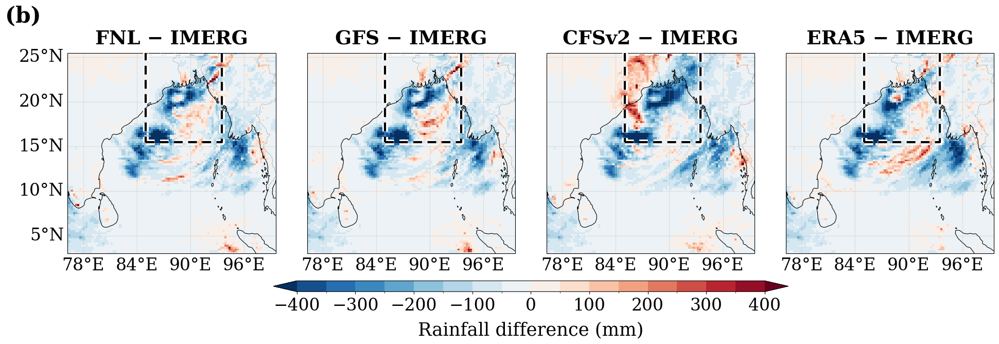

Saved component: /home/ushmo/Desktop/remaL_portfolio/paper_figures/components/Figure_5b_Rainfall_Differences.png


'/home/ushmo/Desktop/remaL_portfolio/paper_figures/components/Figure_5b_Rainfall_Differences.png'

In [13]:
# max_abs is no longer used (FIG5_DIFF_LEVELS are fixed); kept for checking the data range.
max_abs = max(
    np.nanmax(np.abs(wrf_diff[name]))
    for name in MODEL_NAMES
    if np.isfinite(wrf_diff[name]).any()
)
if max_abs == 0:
    max_abs = 1.0

diff_levels = FIG5_DIFF_LEVELS
diff_cmap = plt.get_cmap("RdBu_r")   # <----------------------- change this to use a different colour map
diff_norm = BoundaryNorm(diff_levels, ncolors=diff_cmap.N, extend="both")

# fit_to_widest scales this row to the full printed width
set_map_print_width(MAP_WIDTH_PER_PANEL_IN * 4)
fig, axes = wind_gm_map_row(4)
mesh = None
for i, name in enumerate(MODEL_NAMES):
    ax = axes[i]
    wind_gm_base_map(ax, left_labels=(i == 0))
    mesh = ax.pcolormesh(
        rain_plot_lon,
        rain_plot_lat,
        wrf_diff[name],
        cmap=diff_cmap,
        norm=diff_norm,
        transform=ccrs.PlateCarree(),
        shading="auto"
    )
    draw_verification_box(ax)
    map_title(ax, name + " − IMERG")

wind_gm_colorbar(fig, mesh, "Rainfall difference (mm)", extend="both", ticks=FIG5_DIFF_TICKS)
panel_label(axes[0], "(b)", x=-0.30, y=1.24, fontsize=M["panel"])
save_component(fig, "Figure_5b_Rainfall_Differences")


### (c) Regional mean rainfall-rate evolution on the common 6-hourly support

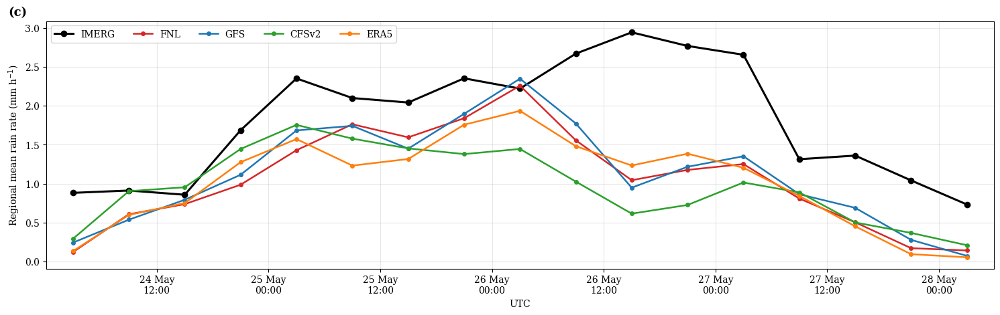

Saved component: /home/ushmo/Desktop/remaL_portfolio/paper_figures/components/Figure_5c_Regional_Rain_Rate.png


'/home/ushmo/Desktop/remaL_portfolio/paper_figures/components/Figure_5c_Regional_Rain_Rate.png'

In [14]:
rain_rate_path = os.path.join(
    ANALYSIS_DIR,
    "A10_rainfall",
    "F07_Regional_6h_Rain_Rate.csv"
)

require_file(rain_rate_path)

rain_rate = pd.read_csv(rain_rate_path)

for column in [
    "start_time_utc",
    "end_time_utc",
    "mid_time_utc"
]:
    rain_rate[column] = pd.to_datetime(rain_rate[column], utc=True)


def draw_rain_rate(ax):
    obs = rain_rate[rain_rate["source"] == "IMERG"]

    ax.plot(
        obs["mid_time_utc"],
        obs["mean_rain_rate_mm_per_h"],
        color=COLORS["IMERG"],
        linewidth=REFERENCE_LINE_WIDTH,
        marker="o",
        label="IMERG"
    )

    for name in MODEL_NAMES:
        s = rain_rate[rain_rate["source"] == name]

        ax.plot(
            s["mid_time_utc"],
            s["mean_rain_rate_mm_per_h"],
            color=COLORS[name],
            linewidth=LINE_WIDTH,
            marker="o",
            markersize=MARKER_SIZE,
            label=name
        )

    ax.set_ylabel("Regional mean rain rate (mm h$^{-1}$)")
    ax.set_xlabel("UTC")
    ax.grid(alpha=GRID_ALPHA)
    ax.legend(ncol=5, frameon=True)
    format_time_axis(ax)


# Wider component so the assembled Figure 5 does not show large white side margins.
fig, ax = plt.subplots(figsize=(14.8, 4.6), constrained_layout=True)   # <----------------------- change this to resize the figure (inches)
draw_rain_rate(ax)
panel_label(ax, "(c)", x=-0.04, y=1.06)
ax.margins(x=0.03)

save_component(
    fig,
    "Figure_5c_Regional_Rain_Rate"
)

### Final paper Figure 5: assembled (a) + (b) + (c)

Saved final PDF: /home/ushmo/Desktop/remaL_portfolio/paper_figures/Figure_5_Rainfall_Validation.pdf
Saved final PNG: /home/ushmo/Desktop/remaL_portfolio/paper_figures/Figure_5_Rainfall_Validation.png


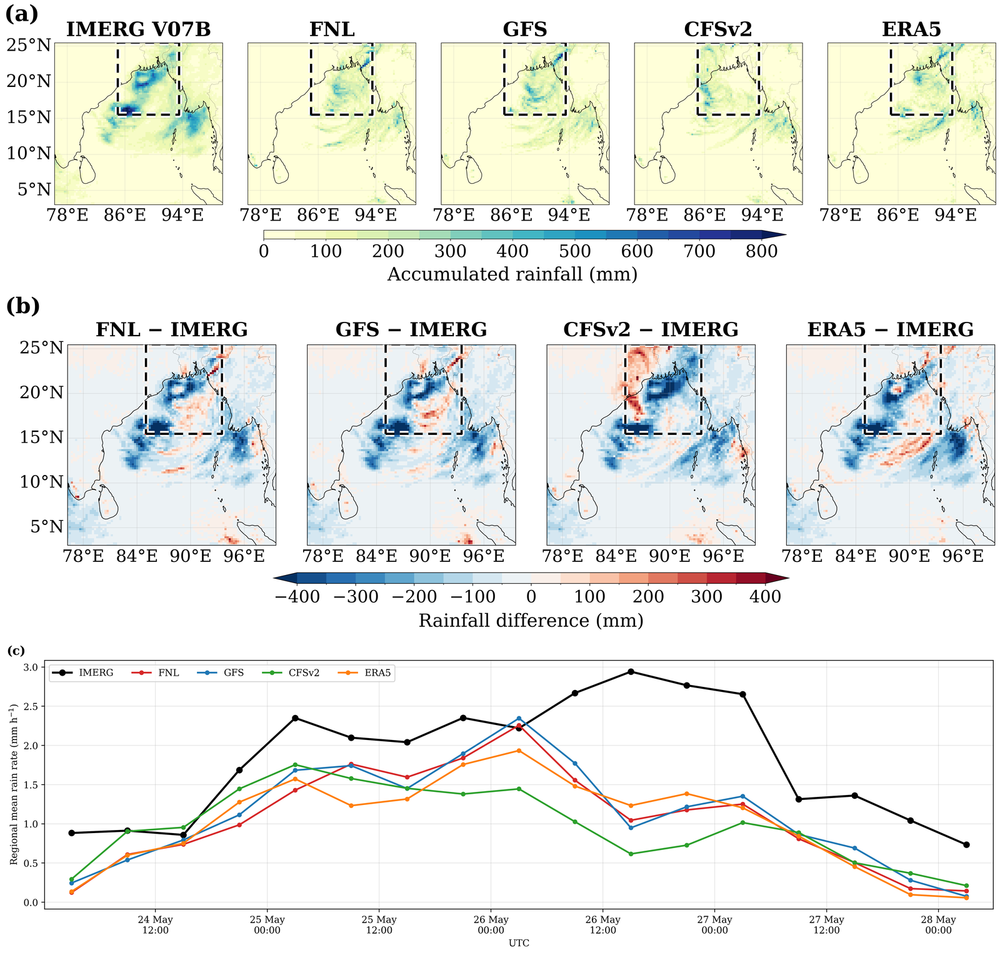

'/home/ushmo/Desktop/remaL_portfolio/paper_figures/Figure_5_Rainfall_Validation.png'

In [15]:
compose_pngs_vertical(
    "Figure_5_Rainfall_Validation",
    [
        os.path.join(COMPONENT_DIR, "Figure_5a_Rainfall_Accumulation.png"),
        os.path.join(COMPONENT_DIR, "Figure_5b_Rainfall_Differences.png"),
        os.path.join(COMPONENT_DIR, "Figure_5c_Regional_Rain_Rate.png"),
    ],
    gap_px=30,   # <----------------------- change this to set the gap between stacked rows (px)
    align="left",
    fit_to_widest=True
)

# Section 3.5 Ocean-surface wind validation against CCMP

## Figure 6. Ocean-surface wind validation against CCMP V3.1 at 1200 UTC 26 May 2024. (a) CCMP and WRF 10-m wind-speed fields with streamlines; (b) WRF-minus-CCMP wind-speed differences. Land points are masked because the comparison is restricted to ocean points; the dashed box marks the verification region used for the CCMP statistics in Table 5.

The analysis notebook did not save these gridded CCMP/WRF comparison fields as a NetCDF extract. The preparation cell below therefore reconstructs the **plot fields only** at the manuscript time. It does **not** recompute or overwrite the paper's CCMP statistics.

**Display-only change in this figure notebook:** the map extent is the full d02 extent used by `wind_gm.py`. CCMP is first interpolated over the whole rectangle for display, then land is masked in every panel (CCMP, WRF and differences) with the WRF land mask, matching the ocean-only verification. The paper's CCMP statistics remain unchanged.

### Prepare Figure 6 fields only

In [16]:
CCMP_FILE_PATTERN = os.path.join(
    CCMP_DIR,
    "CCMP_Wind_Analysis_*_V03.1_L4.nc"
)
ccmp_files = sorted(glob.glob(CCMP_FILE_PATTERN))
if len(ccmp_files) == 0:
    raise FileNotFoundError("No CCMP V3.1 files were found in:\n" + CCMP_DIR)


def nearest_ccmp_slice(when):
    best = None
    best_diff = None
    for path in ccmp_files:
        with xr.open_dataset(path) as ds:
            if "time" not in ds.coords:
                continue
            times = pd.to_datetime(ds["time"].values, utc=True)
            for t in times:
                diff = abs((t - when).total_seconds())
                if best_diff is None or diff < best_diff:
                    best_diff = diff
                    best = (path, t)
    if best is not None and best_diff <= 3600:
        return best
    return None


def read_ccmp_components(when):
    match = nearest_ccmp_slice(when)
    if match is None:
        raise ValueError("No CCMP slice found within 1 h of " + str(when))

    path, matched_time = match
    ds0 = xr.open_dataset(path)
    matched_naive = pd.Timestamp(matched_time).tz_localize(None)
    ds = ds0.sel(time=matched_naive, method="nearest")

    lat_name = "latitude" if "latitude" in ds.coords else "lat"
    lon_name = "longitude" if "longitude" in ds.coords else "lon"
    lat = np.asarray(ds[lat_name].values, dtype=float)
    lon = np.asarray(ds[lon_name].values, dtype=float)

    if "uwnd" in ds and "vwnd" in ds:
        u = np.asarray(ds["uwnd"].values, dtype=float)
        v = np.asarray(ds["vwnd"].values, dtype=float)
    elif "u" in ds and "v" in ds:
        u = np.asarray(ds["u"].values, dtype=float)
        v = np.asarray(ds["v"].values, dtype=float)
    else:
        ds0.close()
        raise KeyError("CCMP u/v wind components were not found.")

    ds0.close()
    lon180 = np.where(lon > 180, lon - 360, lon)
    order = np.argsort(lon180)
    return lat, lon180[order], u[:, order], v[:, order], pd.Timestamp(matched_time)


ccmp_lat, ccmp_lon, ccmp_u_native, ccmp_v_native, ccmp_match_time = read_ccmp_components(FIG6_TIME)

# Keep a small source buffer around d02 before interpolation.
lat_mask = (ccmp_lat >= D02_EXTENT[2] - 1.0) & (ccmp_lat <= D02_EXTENT[3] + 1.0)   # <----------------------- change 1.0 to widen the CCMP source buffer (degrees)
lon_mask = (ccmp_lon >= D02_EXTENT[0] - 1.0) & (ccmp_lon <= D02_EXTENT[1] + 1.0)
c_lat = ccmp_lat[lat_mask]
c_lon = ccmp_lon[lon_mask]
c_u = ccmp_u_native[np.ix_(lat_mask, lon_mask)]
c_v = ccmp_v_native[np.ix_(lat_mask, lon_mask)]

# Full-rectangle plotting interpolation. This intentionally fills land/holes for DISPLAY ONLY.
ccmp_u_common = visual_regrid_fill(c_lon, c_lat, c_u)
ccmp_v_common = visual_regrid_fill(c_lon, c_lat, c_v)
ccmp_speed_common = np.hypot(ccmp_u_common, ccmp_v_common)

wrf_ccmp_fields = {}
for name in MODEL_NAMES:
    wrf_path = os.path.join(
        MODEL_DIRS[name],
        "wrfout_d02_" + FIG6_TIME.strftime("%Y-%m-%d_%H_%M_%S")
    )
    require_file(wrf_path)

    ds = Dataset(wrf_path)
    u10 = np.asarray(ds.variables["U10"][0], dtype=float)
    v10 = np.asarray(ds.variables["V10"][0], dtype=float)
    lat = np.asarray(ds.variables["XLAT"][0], dtype=float)
    lon = np.asarray(ds.variables["XLONG"][0], dtype=float)
    ds.close()

    land = wrf_land_mask(wrf_path)
    speed = np.hypot(u10, v10)
    u_stream, v_stream = wind_gm_streamline_components(lon, lat, u10, v10)
    speed_common = visual_regrid_fill(lon, lat, speed)

    wrf_ccmp_fields[name] = {
        "lat": lat,
        "lon": lon,
        "land": land,
        "speed_native": np.where(land, np.nan, speed),   # ocean only
        "u_stream": u_stream,
        "v_stream": v_stream,
        "speed_common": speed_common,
    }

# Land mask on the 100x100 display grid (same d02 grid in all runs)
_ref = wrf_ccmp_fields[MODEL_NAMES[0]]
LAND_VIS = regrid_nearest(_ref["lon"], _ref["lat"], _ref["land"].astype(float)) > 0.5


def ocean_only(field):
    return np.where(LAND_VIS, np.nan, field)


# Ocean-only fields, matching the analysis notebook (XLAND ocean points only)
ccmp_speed_common = ocean_only(ccmp_speed_common)
ccmp_u_common, ccmp_v_common = ocean_only(ccmp_u_common), ocean_only(ccmp_v_common)
for name in MODEL_NAMES:
    wrf_ccmp_fields[name]["u_stream"] = ocean_only(wrf_ccmp_fields[name]["u_stream"])
    wrf_ccmp_fields[name]["v_stream"] = ocean_only(wrf_ccmp_fields[name]["v_stream"])

ccmp_differences = {
    name: ocean_only(wrf_ccmp_fields[name]["speed_common"]) - ccmp_speed_common
    for name in MODEL_NAMES
}

print("Figure 6 full-d02 display fields ready for", FIG6_TIME)
print("Land masked in all Figure 6 panels:", int(LAND_VIS.sum()), "of", LAND_VIS.size, "display cells are land.")


Figure 6 full-d02 display fields ready for 2024-05-26 12:00:00+00:00
Land masked in all Figure 6 panels: 4112 of 10000 display cells are land.


### (a) CCMP and WRF 10-m wind-speed fields with streamlines

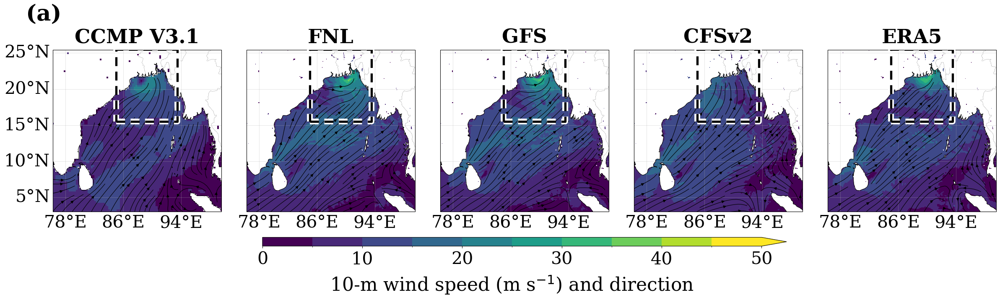

Saved component: /home/ushmo/Desktop/remaL_portfolio/paper_figures/components/Figure_6a_CCMP_WRF_Wind.png


'/home/ushmo/Desktop/remaL_portfolio/paper_figures/components/Figure_6a_CCMP_WRF_Wind.png'

In [17]:
FIG6_SPEED_CLEVS = [0, 5, 10, 15, 20, 25, 30, 35, 40, 45, 50]   # <----------------------- change this to set Figure 6a speed levels (m s-1)
FIG6_SPEED_CMAP = plt.get_cmap("viridis")   # <----------------------- change this to use a different colour map
FIG6_SPEED_NORM = BoundaryNorm(
    FIG6_SPEED_CLEVS,
    ncolors=FIG6_SPEED_CMAP.N,
    clip=True
)

set_map_print_width(MAP_WIDTH_PER_PANEL_IN * 5)
fig, axes = wind_gm_map_row(5)
mesh = None

# CCMP reference, already on the 100×100 full-domain plotting grid.
ax = axes[0]
wind_gm_base_map(ax, left_labels=True, lon_step=MAP_GRID_LON_STEP_NARROW, land_face=LAND_FACE)
mesh = ax.pcolormesh(
    VIS_LON,
    VIS_LAT,
    ccmp_speed_common,
    cmap=FIG6_SPEED_CMAP,
    norm=FIG6_SPEED_NORM,
    transform=ccrs.PlateCarree(),
    shading="auto"
)
ax.streamplot(
    VIS_LON,
    VIS_LAT,
    ccmp_u_common,
    ccmp_v_common,
    transform=ccrs.PlateCarree(),
    color="black",
    linewidth=STREAM_LINEWIDTH,
    density=STREAM_DENSITY,
    arrowsize=STREAM_ARROWSIZE
)
draw_verification_box(ax)
map_title(ax, "CCMP V3.1")

# Four WRF panels: native pcolormesh on ocean points only (land set to NaN
# in the preparation cell), streamlines on the same 100×100 grid used in wind_gm.py.
for i, name in enumerate(MODEL_NAMES, start=1):
    ax = axes[i]
    d = wrf_ccmp_fields[name]
    wind_gm_base_map(ax, left_labels=False, lon_step=MAP_GRID_LON_STEP_NARROW, land_face=LAND_FACE)
    mesh = ax.pcolormesh(
        d["lon"],
        d["lat"],
        d["speed_native"],
        cmap=FIG6_SPEED_CMAP,
        norm=FIG6_SPEED_NORM,
        transform=ccrs.PlateCarree(),
        shading="auto"
    )
    ax.streamplot(
        VIS_LON,
        VIS_LAT,
        d["u_stream"],
        d["v_stream"],
        transform=ccrs.PlateCarree(),
        color="black",
        linewidth=STREAM_LINEWIDTH,
        density=STREAM_DENSITY,
        arrowsize=STREAM_ARROWSIZE
    )
    draw_verification_box(ax)
    map_title(ax, name)

wind_gm_colorbar(
    fig,
    mesh,
    "10-m wind speed (m s$^{-1}$) and direction",
    extend="max"
)
panel_label_above_title(axes[0], "(a)")
save_component(fig, "Figure_6a_CCMP_WRF_Wind")


### (b) WRF-minus-CCMP wind-speed differences

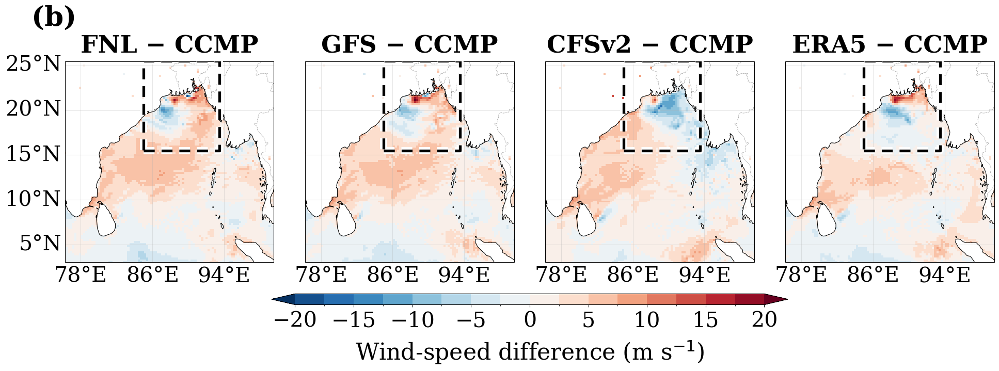

Saved component: /home/ushmo/Desktop/remaL_portfolio/paper_figures/components/Figure_6b_WRF_minus_CCMP.png


'/home/ushmo/Desktop/remaL_portfolio/paper_figures/components/Figure_6b_WRF_minus_CCMP.png'

In [18]:
# max_abs is no longer used (FIG6_DIFF_LEVELS are fixed); kept for checking the data range.
max_abs = max(
    np.nanmax(np.abs(ccmp_differences[name]))
    for name in MODEL_NAMES
    if np.isfinite(ccmp_differences[name]).any()
)
if max_abs == 0:
    max_abs = 1.0

FIG6_DIFF_CLEVS = FIG6_DIFF_LEVELS
FIG6_DIFF_CMAP = plt.get_cmap("RdBu_r")   # <----------------------- change this to use a different colour map
FIG6_DIFF_NORM = BoundaryNorm(
    FIG6_DIFF_CLEVS,
    ncolors=FIG6_DIFF_CMAP.N,
    extend="both"
)

# Figure 6 is stacked without rescaling: row (b) prints narrower than row (a)
set_map_print_width(MAP_WIDTH_PER_PANEL_IN * 4, PRINT_TEXT_WIDTH_IN * 4 / 5)
fig, axes = wind_gm_map_row(4)
mesh = None
for i, name in enumerate(MODEL_NAMES):
    ax = axes[i]
    wind_gm_base_map(ax, left_labels=(i == 0), lon_step=MAP_GRID_LON_STEP_NARROW, land_face=LAND_FACE)
    mesh = ax.pcolormesh(
        VIS_LON,
        VIS_LAT,
        ccmp_differences[name],
        cmap=FIG6_DIFF_CMAP,
        norm=FIG6_DIFF_NORM,
        transform=ccrs.PlateCarree(),
        shading="auto"
    )
    draw_verification_box(ax)
    map_title(ax, name + " − CCMP")

wind_gm_colorbar(
    fig,
    mesh,
    "Wind-speed difference (m s$^{-1}$)",
    extend="both",
    ticks=FIG6_DIFF_TICKS
)
panel_label_above_title(axes[0], "(b)")
save_component(fig, "Figure_6b_WRF_minus_CCMP")


### Final paper Figure 6: assembled (a) + (b)

Saved final PDF: /home/ushmo/Desktop/remaL_portfolio/paper_figures/Figure_6_CCMP_Ocean_Wind_Validation.pdf
Saved final PNG: /home/ushmo/Desktop/remaL_portfolio/paper_figures/Figure_6_CCMP_Ocean_Wind_Validation.png


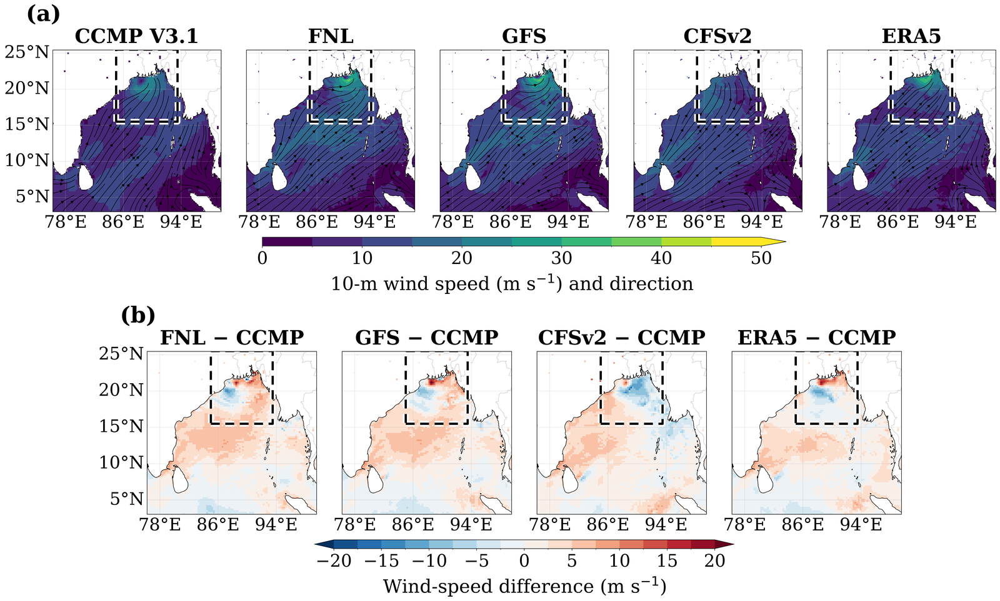

'/home/ushmo/Desktop/remaL_portfolio/paper_figures/Figure_6_CCMP_Ocean_Wind_Validation.png'

In [19]:
compose_pngs_vertical(
    "Figure_6_CCMP_Ocean_Wind_Validation",
    [
        os.path.join(COMPONENT_DIR, "Figure_6a_CCMP_WRF_Wind.png"),
        os.path.join(COMPONENT_DIR, "Figure_6b_WRF_minus_CCMP.png"),
    ],
    gap_px=30   # <----------------------- change this to set the gap between stacked rows (px)
)


# Section 3.6 Moisture and surface latent heat flux

## Figure 7. Thermodynamic diagnostics. (a) Precipitable water (PW) and 850-hPa relative humidity (RH850) at 1200 UTC 26 May 2024; (b) WRF surface latent heat flux from the LH diagnostic (W m$^{-2}$), area-averaged over the dashed box in (a) (85.0–93.5°E, 15.5–25.5°N) from 0600 UTC 24 May through the analysis period. All fields are derived from the WRF experiments.

### (a) Precipitable water and 850-hPa relative humidity at 1200 UTC 26 May 2024

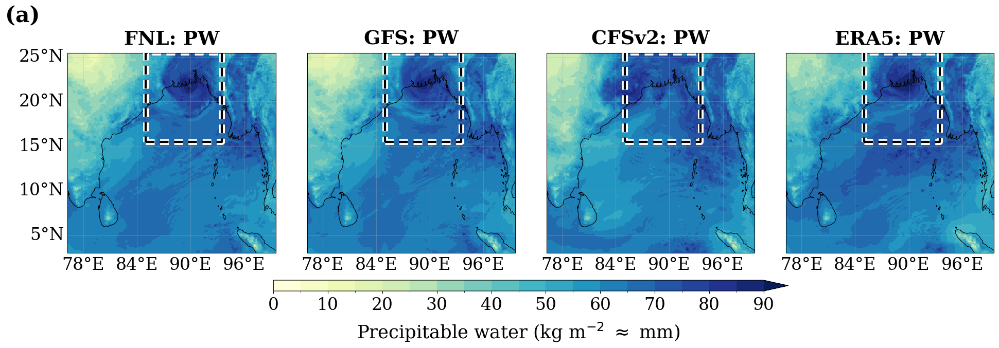

Saved component: /home/ushmo/Desktop/remaL_portfolio/paper_figures/components/Figure_7a1_PW.png


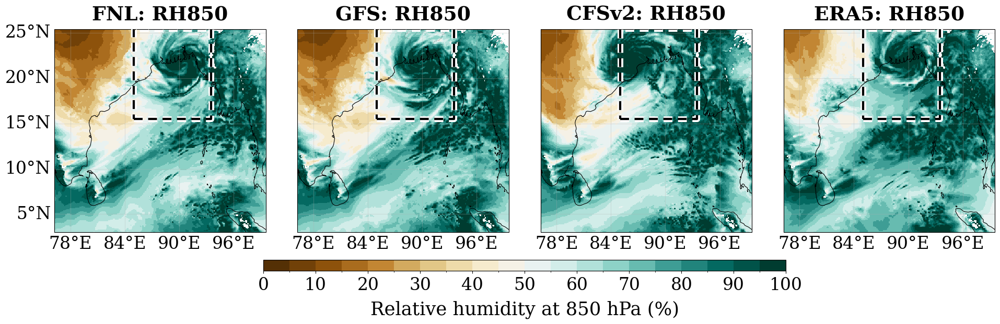

Saved component: /home/ushmo/Desktop/remaL_portfolio/paper_figures/components/Figure_7a2_RH850.png


'/home/ushmo/Desktop/remaL_portfolio/paper_figures/components/Figure_7a2_RH850.png'

In [20]:
moisture_data = {}

for name in MODEL_NAMES:
    path = os.path.join(
        ANALYSIS_DIR,
        "A12_moisture_flux",
        "A12_" + name + "_" + FIG7_TIME_TEXT + "_PW_RH850.nc"
    )
    require_file(path)
    ds = xr.open_dataset(path)
    moisture_data[name] = {
        "pw": np.asarray(ds["precipitable_water"].values, dtype=float),
        "rh850": np.asarray(ds["rh850"].values, dtype=float),
        "lat": np.asarray(ds["latitude"].values, dtype=float),
        "lon": np.asarray(ds["longitude"].values, dtype=float),
    }
    ds.close()

# ---------- PW row ----------
pw_levels = FIG7_PW_LEVELS
pw_cmap = plt.get_cmap("YlGnBu")   # <----------------------- change this to use a different colour map
pw_norm = BoundaryNorm(pw_levels, ncolors=pw_cmap.N, extend="max")

set_map_print_width(MAP_WIDTH_PER_PANEL_IN * 4)
fig, axes = wind_gm_map_row(4)
mesh = None
for i, name in enumerate(MODEL_NAMES):
    d = moisture_data[name]
    ax = axes[i]
    wind_gm_base_map(ax, left_labels=(i == 0))
    mesh = ax.pcolormesh(
        d["lon"],
        d["lat"],
        d["pw"],
        cmap=pw_cmap,
        norm=pw_norm,
        transform=ccrs.PlateCarree(),
        shading="auto"
    )
    draw_verification_box(ax)
    map_title(ax, name + ": PW")

wind_gm_colorbar(
    fig,
    mesh,
    r"Precipitable water (kg m$^{-2}$ $\approx$ mm)",
    extend="max",
    ticks=FIG7_PW_TICKS
)
panel_label(axes[0], "(a)", x=-0.30, y=1.24, fontsize=M["panel"])
save_component(fig, "Figure_7a1_PW")

# ---------- RH850 row ----------
rh_levels = FIG7_RH_LEVELS
rh_cmap = plt.get_cmap("BrBG")   # <----------------------- change this to use a different colour map
rh_norm = BoundaryNorm(rh_levels, ncolors=rh_cmap.N, clip=True)

set_map_print_width(MAP_WIDTH_PER_PANEL_IN * 4)
fig, axes = wind_gm_map_row(4)
mesh = None
for i, name in enumerate(MODEL_NAMES):
    d = moisture_data[name]
    ax = axes[i]
    wind_gm_base_map(ax, left_labels=(i == 0))
    mesh = ax.pcolormesh(
        d["lon"],
        d["lat"],
        d["rh850"],
        cmap=rh_cmap,
        norm=rh_norm,
        transform=ccrs.PlateCarree(),
        shading="auto"
    )
    draw_verification_box(ax)
    map_title(ax, name + ": RH850")

wind_gm_colorbar(
    fig,
    mesh,
    "Relative humidity at 850 hPa (%)",
    extend="neither",
    ticks=FIG7_RH_TICKS
)
save_component(fig, "Figure_7a2_RH850")


### (b) Area-averaged WRF surface latent heat flux through the analysis period

Dropping initial-time LH at 2024-05-24 00:00:00+00:00


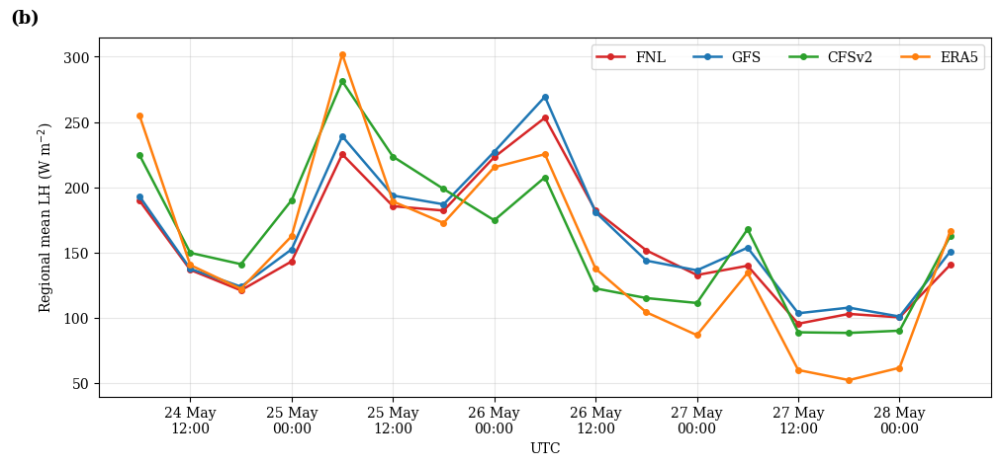

Saved component: /home/ushmo/Desktop/remaL_portfolio/paper_figures/components/Figure_7b_Latent_Heat_Flux.png


'/home/ushmo/Desktop/remaL_portfolio/paper_figures/components/Figure_7b_Latent_Heat_Flux.png'

In [21]:
lh_path = os.path.join(
    ANALYSIS_DIR,
    "A12_moisture_flux",
    "A12_regional_latent_heat_flux.csv"
)

require_file(
    lh_path
)

lh_table = pd.read_csv(
    lh_path
)

lh_table["time_utc"] = pd.to_datetime(
    lh_table["time_utc"],
    utc=True
)

if LH_DROP_INITIAL_TIME:
    # WRF writes LH = 0 at the initial time; it is not a physical flux value.
    first_time = lh_table["time_utc"].min()
    print("Dropping initial-time LH at", first_time)
    lh_table = lh_table[lh_table["time_utc"] > first_time]


def draw_latent_heat_flux(
    ax
):

    for name in MODEL_NAMES:

        s = lh_table[
            lh_table["model"]
            == name
        ].sort_values(
            "time_utc"
        )

        ax.plot(
            s["time_utc"],
            s["regional_mean_LH"],
            color=COLORS[name],
            linewidth=LINE_WIDTH,
            marker="o",
            markersize=MARKER_SIZE,
            label=name
        )

    ax.set_ylabel(
        "Regional mean LH (W m$^{-2}$)"
    )

    ax.set_xlabel(
        "UTC"
    )

    ax.grid(
        alpha=GRID_ALPHA
    )

    ax.legend(
        ncol=4,
        frameon=True
    )

    format_time_axis(
        ax
    )


fig, ax = plt.subplots(
    figsize=(10.0, 4.6),   # <----------------------- change this to resize the figure (inches)
    constrained_layout=True
)

draw_latent_heat_flux(
    ax
)

panel_label(
    ax,
    "(b)"
)

save_component(
    fig,
    "Figure_7b_Latent_Heat_Flux"
)

### Final paper Figure 7: assembled (a) + (b)

Saved final PDF: /home/ushmo/Desktop/remaL_portfolio/paper_figures/Figure_7_Thermodynamic_Diagnostics.pdf
Saved final PNG: /home/ushmo/Desktop/remaL_portfolio/paper_figures/Figure_7_Thermodynamic_Diagnostics.png


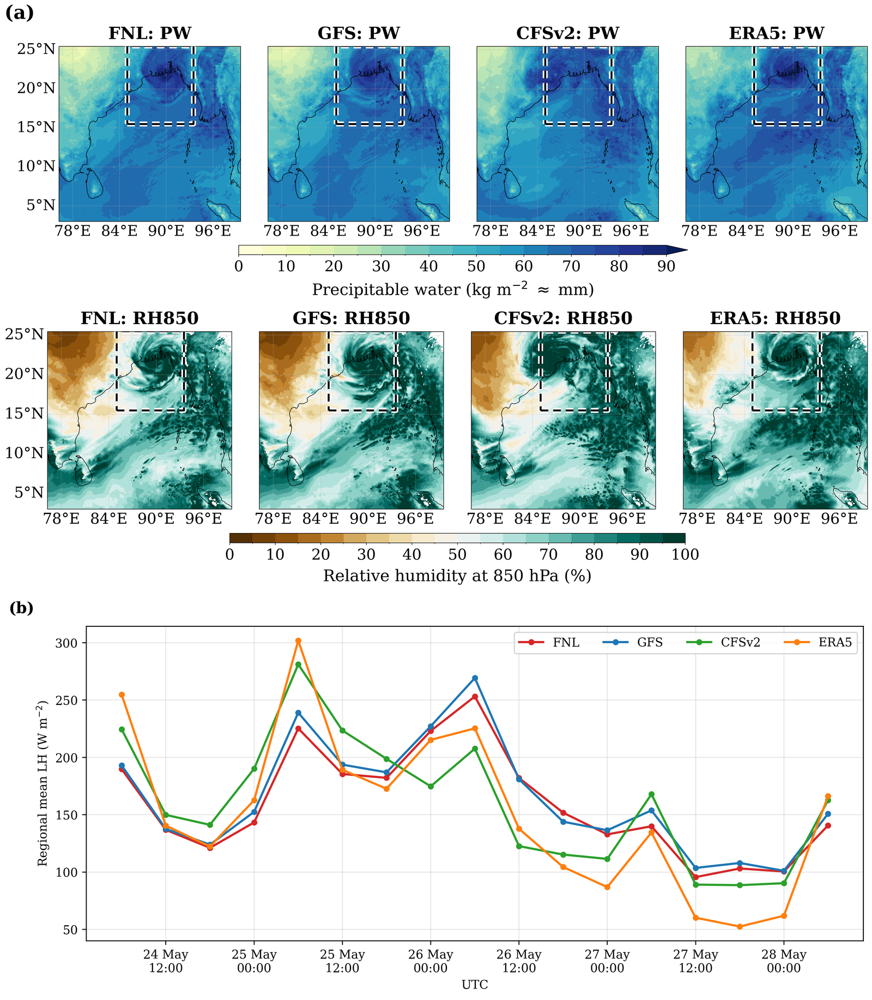

'/home/ushmo/Desktop/remaL_portfolio/paper_figures/Figure_7_Thermodynamic_Diagnostics.png'

In [22]:
compose_pngs_vertical(
    "Figure_7_Thermodynamic_Diagnostics",
    [
        os.path.join(COMPONENT_DIR, "Figure_7a1_PW.png"),
        os.path.join(COMPONENT_DIR, "Figure_7a2_RH850.png"),
        os.path.join(COMPONENT_DIR, "Figure_7b_Latent_Heat_Flux.png"),
    ],
    gap_px=30,   # <----------------------- change this to set the gap between stacked rows (px)
    align="left",
    fit_to_widest=True
)

# Section 3.7 Environmental vertical wind shear and storm-centered structure

## Figure 8. Environmental and storm-structure diagnostics. (a) 850–200-hPa environmental vertical wind shear averaged over the 200–500 km storm-relative annulus; (b) storm-centered east–west vertical sections at 1200 UTC 26 May 2024, with horizontal wind speed shaded and vertical velocity contoured at −1, −0.5, 0.5, 1, 2, and 4 m s$^{-1}$ (solid, ascent; dashed, descent).

### (a) 850–200-hPa environmental vertical wind shear averaged over the 200–500 km storm-relative annulus

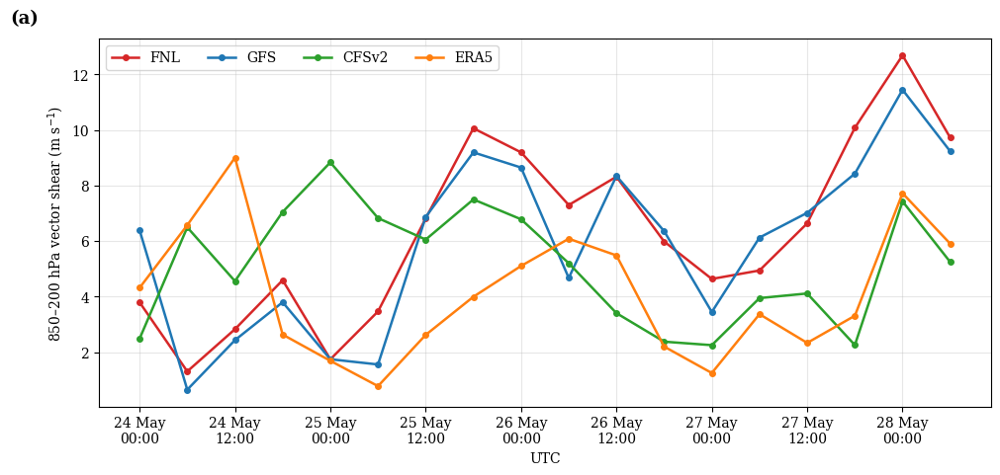

Saved component: /home/ushmo/Desktop/remaL_portfolio/paper_figures/components/Figure_8a_Environmental_Shear.png


'/home/ushmo/Desktop/remaL_portfolio/paper_figures/components/Figure_8a_Environmental_Shear.png'

In [23]:
shear_path = os.path.join(
    ANALYSIS_DIR,
    "A13_shear",
    "A13_850_200hPa_environmental_shear.csv"
)

require_file(
    shear_path
)

shear = pd.read_csv(
    shear_path
)

shear["time_utc"] = pd.to_datetime(
    shear["time_utc"],
    utc=True
)


def draw_shear(
    ax
):

    for name in MODEL_NAMES:

        s = shear[
            shear["model"]
            == name
        ].sort_values(
            "time_utc"
        )

        if "coverage_ok" in s.columns:

            good = (
                s["coverage_ok"]
                .astype(str)
                .str.lower()
                .isin(
                    [
                        "true",
                        "1"
                    ]
                )
            )

        else:

            good = pd.Series(
                True,
                index=s.index
            )

        ax.plot(
            s.loc[
                good,
                "time_utc"
            ],
            s.loc[
                good,
                "shear_850_200_ms"
            ],
            color=COLORS[name],
            linewidth=LINE_WIDTH,
            marker="o",
            markersize=MARKER_SIZE,
            label=name
        )

        bad = ~good

        if bad.any():

            ax.scatter(
                s.loc[
                    bad,
                    "time_utc"
                ],
                s.loc[
                    bad,
                    "shear_850_200_ms"
                ],
                marker="x",
                s=40,
                color=COLORS[name]
            )

    ax.set_ylabel(
        "850–200 hPa vector shear (m s$^{-1}$)"
    )

    ax.set_xlabel(
        "UTC"
    )

    ax.grid(
        alpha=GRID_ALPHA
    )

    ax.legend(
        ncol=4,
        frameon=True
    )

    format_time_axis(
        ax
    )


fig, ax = plt.subplots(
    figsize=(10.0, 4.7),   # <----------------------- change this to resize the figure (inches)
    constrained_layout=True
)

draw_shear(
    ax
)

panel_label(
    ax,
    "(a)"
)

save_component(
    fig,
    "Figure_8a_Environmental_Shear"
)

### (b) Storm-centered east–west vertical sections at 1200 UTC 26 May 2024

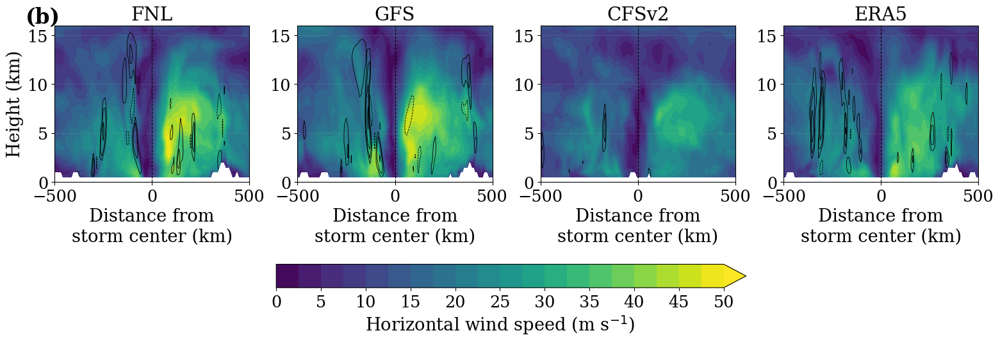

Saved component: /home/ushmo/Desktop/remaL_portfolio/paper_figures/components/Figure_8b_Vertical_Sections.png


'/home/ushmo/Desktop/remaL_portfolio/paper_figures/components/Figure_8b_Vertical_Sections.png'

In [24]:
vertical_sections = {}

for name in MODEL_NAMES:

    path = os.path.join(
        ANALYSIS_DIR,
        "A14_vertical_sections",
        "A14_"
        + name
        + "_"
        + FIG8_TIME_TEXT
        + "_vertical_section.nc"
    )

    require_file(
        path
    )

    ds = xr.open_dataset(
        path
    )

    vertical_sections[name] = {
        "wind": np.asarray(
            ds[
                "horizontal_wind_speed"
            ].values,
            dtype=float
        ),
        "w": np.asarray(
            ds[
                "vertical_velocity"
            ].values,
            dtype=float
        ),
        "z_km": np.asarray(
            ds[
                "height_km"
            ].values,
            dtype=float
        ),
        "x_km": np.asarray(
            ds[
                "distance_km"
            ].values,
            dtype=float
        )
    }

    ds.close()


FIG8_WIND_CMAP = "viridis"   # <----------------------- change this to use a different colour map


def draw_vertical_section_group(
    fig,
    subspec
):

    sub = subspec.subgridspec(
        1,
        4
    )

    axes = []

    # Print-size fonts for the 2-D sections only (figure printed at full width)
    set_map_print_width(fig.get_figwidth())

    wind_levels = FIG8_WIND_LEVELS

    # Fixed, documented contour levels: dashed = descent, solid = ascent
    w_levels = sorted(FIG8_W_LEVELS)
    w_styles = [
        "dashed" if level < 0 else "solid"
        for level in w_levels
    ]

    handle = None

    for i, name in enumerate(
        MODEL_NAMES
    ):

        s = vertical_sections[name]

        ax = fig.add_subplot(
            sub[0, i]
        )

        handle = ax.contourf(
            s["x_km"],
            s["z_km"],
            s["wind"],
            levels=wind_levels,
            cmap=FIG8_WIND_CMAP,
            extend="max"
        )

        ax.contour(
            s["x_km"],
            s["z_km"],
            s["w"],
            levels=w_levels,
            colors="black",
            linewidths=0.6,
            linestyles=w_styles
        )

        ax.axvline(
            0,
            color="black",
            linestyle="--",
            linewidth=0.8
        )

        ax.set_title(
            name,
            fontsize=M["title"]
        )

        ax.set_xlabel(
            "Distance from\nstorm center (km)",
            fontsize=M["label"]
        )

        ax.tick_params(
            labelsize=M["tick"]
        )

        ax.grid(
            alpha=0.15
        )

        ax.set_ylim(
            0,
            16   # <----------------------- change this to match CROSS_SECTION_TOP_KM (km)
        )

        if i == 0:

            ax.set_ylabel(
                "Height (km)",
                fontsize=M["label"]
            )

        axes.append(
            ax
        )


    cbar = fig.colorbar(
        handle,
        ax=axes,
        orientation="horizontal",
        pad=0.10,
        shrink=0.75
    )

    cbar.set_ticks(
        FIG8_WIND_TICKS
    )

    cbar.set_label(
        "Horizontal wind speed (m s$^{-1}$)",
        fontsize=M["cbar_label"]
    )

    cbar.ax.tick_params(
        labelsize=M["cbar_tick"]
    )

    return axes


fig = plt.figure(
    figsize=(15.5, 5.3),   # <----------------------- change this to resize the figure (inches)
    constrained_layout=True
)

gs = fig.add_gridspec(
    1,
    1
)

axes = draw_vertical_section_group(
    fig,
    gs[0, 0]
)

panel_label(
    axes[0],
    "(b)",
    x=-0.15,
    y=1.12,
    fontsize=M["panel"]
)

save_component(
    fig,
    "Figure_8b_Vertical_Sections"
)

### Final paper Figure 8: assembled (a) + (b)

Saved final PNG: /home/ushmo/Desktop/remaL_portfolio/paper_figures/Figure_8_Shear_and_Storm_Structure.png
Saved final PDF: /home/ushmo/Desktop/remaL_portfolio/paper_figures/Figure_8_Shear_and_Storm_Structure.pdf


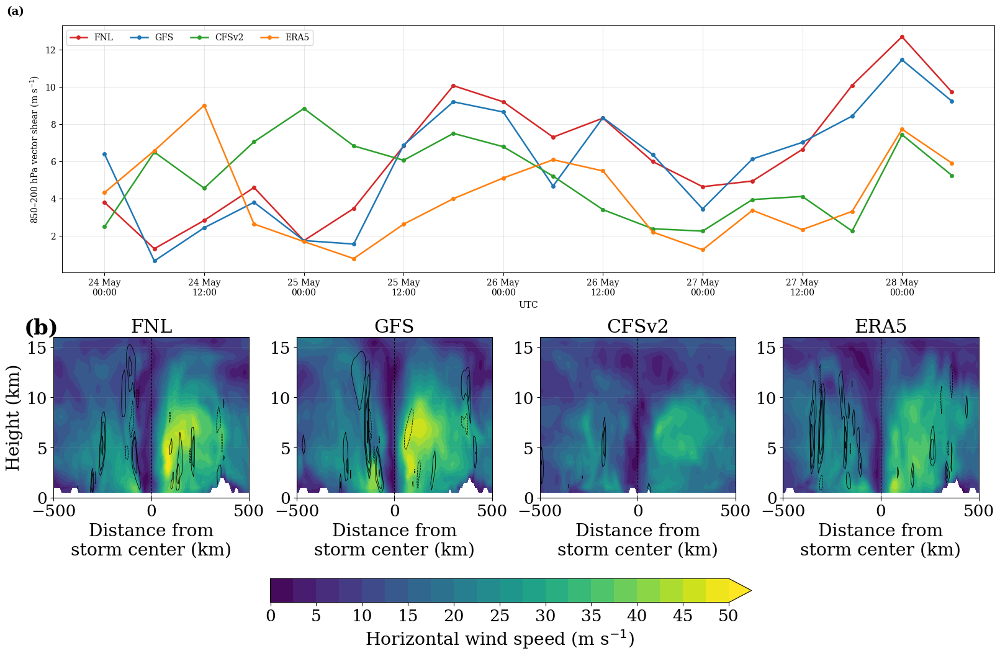

'/home/ushmo/Desktop/remaL_portfolio/paper_figures/Figure_8_Shear_and_Storm_Structure.png'

In [25]:
fig = plt.figure(
    figsize=(16.0, 10.5),   # <----------------------- change this to resize the figure (inches)
    constrained_layout=True
)

outer = fig.add_gridspec(
    2,
    1,
    height_ratios=[
        0.72,
        1.0
    ]
)

ax_a = fig.add_subplot(
    outer[0, 0]
)

draw_shear(
    ax_a
)

panel_label(
    ax_a,
    "(a)",
    x=-0.06,
    y=1.08
)

axes_b = draw_vertical_section_group(
    fig,
    outer[1, 0]
)

panel_label(
    axes_b[0],
    "(b)",
    x=-0.15,
    y=1.12,
    fontsize=M["panel"]
)

save_final(
    fig,
    "Figure_8_Shear_and_Storm_Structure"
)

# Final paper-figure check

Run this after generating all final figures. It only checks filenames, not scientific content.

In [26]:
expected_final_figures = [
    "Figure_1_Domain_and_IMD_Track.png",
    "Figure_2_Track_and_Motion_Validation.png",
    "Figure_3_Intensity_Validation.png",
    "Figure_4_Landfall_Crossings.png",
    "Figure_5_Rainfall_Validation.png",
    "Figure_6_CCMP_Ocean_Wind_Validation.png",
    "Figure_7_Thermodynamic_Diagnostics.png",
    "Figure_8_Shear_and_Storm_Structure.png",
]

rows = []

for filename in expected_final_figures:

    path = os.path.join(
        PAPER_FIGURE_DIR,
        filename
    )

    rows.append(
        {
            "figure": filename,
            "exists": os.path.exists(path),
            "path": path
        }
    )


check_table = pd.DataFrame(
    rows
)

print(
    check_table.to_string(
        index=False
    )
)

missing = check_table[
    ~check_table["exists"]
]

if len(missing) == 0:

    print(
        "\nAll 8 final manuscript figures are present."
    )

else:

    print(
        "\nMissing final figures:"
    )

    print(
        missing["figure"].to_string(
            index=False
        )
    )

                                  figure  exists                                                                                       path
       Figure_1_Domain_and_IMD_Track.png    True        /home/ushmo/Desktop/remaL_portfolio/paper_figures/Figure_1_Domain_and_IMD_Track.png
Figure_2_Track_and_Motion_Validation.png    True /home/ushmo/Desktop/remaL_portfolio/paper_figures/Figure_2_Track_and_Motion_Validation.png
       Figure_3_Intensity_Validation.png    True        /home/ushmo/Desktop/remaL_portfolio/paper_figures/Figure_3_Intensity_Validation.png
         Figure_4_Landfall_Crossings.png    True          /home/ushmo/Desktop/remaL_portfolio/paper_figures/Figure_4_Landfall_Crossings.png
        Figure_5_Rainfall_Validation.png    True         /home/ushmo/Desktop/remaL_portfolio/paper_figures/Figure_5_Rainfall_Validation.png
 Figure_6_CCMP_Ocean_Wind_Validation.png    True  /home/ushmo/Desktop/remaL_portfolio/paper_figures/Figure_6_CCMP_Ocean_Wind_Validation.png
  Figure_7_Thermodyn